# Which loss can carry an entropy claim

This PR profiles "the bottom of the training loss" and asks whether 0.55-0.58 nats/token is close
to the conditional entropy of the corpus under this encoding. The question this notebook settles
is narrower and comes first: **can a training loss carry that claim at all?**

It cannot, and the reason is not that validation is a nicer metric. For any model $q$ and any true
distribution $p$, on data drawn from $p$ and not used to fit $q$,

$$\mathbb{E}_p\!\left[-\log q(x)\right] \;=\; H(p) \;+\; D_{\mathrm{KL}}(p \,\|\, q) \;\ge\; H(p).$$

Held-out CE is therefore **an upper bound on the entropy**, and the tightest one available.
Training CE has no such relation: it measures fit to the empirical distribution of the sample $q$
was fitted on, and with enough capacity it goes to zero on any finite sample. A flat training
curve says the optimiser stopped improving on the training sample. It says nothing about $H(p)$.

Everything below is recomputed from files committed in this repository. The first pass had two
slices that differed in **both** leakage and time period, so it could not say which of the two
its number came from; `valset_v1` -- frozen, leak-free, the same 488 tickers over the same
2022-2025 window -- fills the missing cell, and five further leak-free slices measure what the
period alone does. Nine slices in `data/`, same checkpoint and evaluator
throughout, plus three evidence tables from the validation-set inventory (#51) in `data/`.

**Reading order.** Eight figures carry the argument; two tables at the end hold the numbers.

In [1]:
%matplotlib inline
import csv, hashlib, json, math
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

HERE = Path("docs/experiments/trainloss_profiling_20260826") if Path("docs").is_dir() else Path(".")
DATA = HERE / "data"
ART = DATA          # the five ce-by-position records this notebook reads sit next to the CSVs

LN2 = math.log(2)
TOK_PER_MSG = 26
EVAL_SPEC_TOKENS, EVAL_SPEC_SIGMA = 5e7, 0.002   # test_ce_eval_spec.md line 42

# --- palette -------------------------------------------------------------------------
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GOOD, WARN, SERIOUS, CRIT = "#0ca30c", "#fab219", "#ec835a", "#d03b3b"
BLUE_RAMP = ["#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#2a78d6",
             "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
def ramp(n):
    # n ordered steps of the blue ramp, dark end reserved for the largest value
    idx = np.linspace(0, len(BLUE_RAMP) - 1, n).round().astype(int)
    return [BLUE_RAMP[i] for i in idx]

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 300, "savefig.dpi": 300, "font.size": 7.41,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 8.19, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.62,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "legend.frameon": False, "lines.linewidth": 1.56, "axes.spines.top": False,
    "axes.spines.right": False,
})

def show(fig):
    # Palette-quantised PNG: this notebook is committed with outputs so GitHub renders it
    # inline, and GitHub stops rendering large notebooks. Flat chart colours quantise to
    # 128 with no visible loss and about a third of the bytes. Falls back where Pillow
    # is absent, at the cost of a bigger file.
    try:
        from io import BytesIO
        from IPython.display import Image as _Img, display as _display
        from PIL import Image as _PIL
    except ImportError:
        plt.show(); return
    buf = BytesIO(); fig.savefig(buf, format="png", facecolor=SURFACE); plt.close(fig)
    buf.seek(0)
    im = _PIL.open(buf).convert("RGB").quantize(colors=128, dither=_PIL.Dither.NONE)
    out = BytesIO(); im.save(out, "PNG", optimize=True)
    _display(_Img(data=out.getvalue(), format="png"))

def tidy(ax, xlab=None, ylab=None, title=None):
    if xlab: ax.set_xlabel(xlab)
    if ylab: ax.set_ylabel(ylab)
    if title: ax.set_title(title, pad=7.02)
    ax.set_axisbelow(True)
    return ax

# --- inputs --------------------------------------------------------------------------
STEM = "j5749206_9o8um51n_5749206"

def slice_(label):
    p = ART / f"{STEM}_{label}.json"
    return json.loads(p.read_text()) if p.is_file() else None

# The three matched slices that carry the decomposition. Same checkpoint, same
# evaluator, 128 sequences each; they differ in exactly one thing per pair.
tr = slice_("train_period_v2")      # GOOG 2025-12       trained on        in window
va = slice_("valset_2025")          # valset 2025-01..11 never trained on  in window
ho = slice_("heldout_v2")           # GOOG 2026-01       never trained on  after it

# Leak-free slices that differ only in period. These say how much of the A->C
# difference above could be period rather than memory.
PERIODS = [("valset_2022", "2022"), ("valset_2023", "2023"), ("valset_2024", "2024"),
           ("valset_2025h1", "2025 H1"), ("valset_2025h2", "2025 H2"),
           ("valset_2025", "2025 (Jan-Nov)"), ("valset_all", "2022-2025 pooled")]
periods = {lab: (slice_(k), k) for k, lab in PERIODS if slice_(k)}

# The first pass, kept for the eval-budget comparison only: 64 sequences per slice.
tr64, ho64 = slice_("train_period"), slice_("heldout")
# --- the period correction ------------------------------------------------------------
# A is December and C is the January-November mean, and CE is not flat across that span:
# it falls monotonically year over year and keeps falling inside 2025. So part of A -> C
# is the model meeting easier data rather than remembering it. H1's midpoint is mid-March
# and H2's is end-August, 5.5 months apart; December is 3.5 months past H2's.
h1s, h2s = slice_("valset_2025h1"), slice_("valset_2025h2")
if h1s and h2s:
    E1, E2 = h1s["aggregate"]["ce"], h2s["aggregate"]["ce"]
    SLOPE = (E2 - E1) / 5.5                       # nats per month, within 2025
    DEC_EXPECTED = E2 + 3.5 * SLOPE               # what December should read on period alone
else:
    E1 = E2 = SLOPE = DEC_EXPECTED = None
ruler = pd.read_csv(DATA / "ruler_by_size.csv")                     # #51: 3 held-out rulers x 12 sizes
axis_fits = pd.read_csv(DATA / "axis_fits.csv")                     # #51: what the ruler does to alpha
inventory = pd.read_csv(DATA / "validation_sets_inventory.csv")     # #51: what each set is

def per(x, key, cols=("ce",)):
    d = pd.DataFrame(x[key])
    keep = (["position"] if key == "per_position" else ["field", "width"]) + list(cols)
    return d[keep]

pos = (per(tr, "per_position", ("ce", "unigram_nats", "ceiling_nats", "field"))
       .rename(columns={"ce": "train"})
       .merge(per(va, "per_position").rename(columns={"ce": "valset"}), on="position")
       .merge(per(ho, "per_position").rename(columns={"ce": "held"}), on="position"))
pos["memorisation"] = pos.valset - pos.train      # period fixed, leakage varies
pos["tshift"] = pos.held - pos.valset              # leakage fixed, period varies
pos["gap"] = pos.held - pos.train                 # what the first pass measured

fld = (per(tr, "per_field", ("ce", "unigram_nats", "ceiling_nats"))
       .rename(columns={"ce": "train"})
       .merge(per(va, "per_field", ("ce", "ce_share_pct"))[["field", "ce", "ce_share_pct"]]
              .rename(columns={"ce": "valset", "ce_share_pct": "valset_share"}), on="field")
       .merge(per(ho, "per_field")[["field", "ce"]].rename(columns={"ce": "held"}), on="field"))
fld["memorisation"] = fld.valset - fld.train
fld["tshift"] = fld.held - fld.valset
fld["gap"] = fld.held - fld.train
fld["held_share"] = fld.valset_share
fld["mem_share"] = 100 * fld.memorisation * fld.width / (fld.memorisation * fld.width).sum()

# The period effect per field, on data the model never trained on. If the in-sample
# advantage is really period, these columns have the same shape -- a comparison that does
# not lean on the December extrapolation.
y24 = slice_("valset_2024")
if y24:
    fld = fld.merge(per(y24, "per_field")[["field", "ce"]].rename(
        columns={"ce": "ce_2024"}), on="field")
    fld["period_year"] = fld.ce_2024 - fld.valset
if h1s and h2s:
    fld = (fld.merge(per(h1s, "per_field")[["field", "ce"]].rename(
               columns={"ce": "ce_h1"}), on="field")
              .merge(per(h2s, "per_field")[["field", "ce"]].rename(
               columns={"ce": "ce_h2"}), on="field"))
    fld["period_within"] = fld.ce_h1 - fld.ce_h2
fld["gap_weighted"] = fld.gap * fld.width
fld["gap_share"] = 100 * fld.gap_weighted / fld.gap_weighted.sum()
# how much of the no-context (unigram) entropy the model actually removed
# measured on the leak-free in-window slice: the only column that estimates what the
# model actually knows rather than what it remembers
fld["recovered_pct"] = np.where(fld.unigram_nats > 0.05,
                                100 * (fld.unigram_nats - fld.valset) / fld.unigram_nats, np.nan)
fld = fld.sort_values("held_share", ascending=False).reset_index(drop=True)

MESSAGES = tr["slice"]["messages"]     # per matched slice

CE_TR, CE_VA, CE_HO = (x["aggregate"]["ce"] for x in (tr, va, ho))
def bits(ce): return ce * TOK_PER_MSG / LN2
BITS_TR, BITS_VA, BITS_HO = bits(CE_TR), bits(CE_VA), bits(CE_HO)
MEM, SHIFT = CE_VA - CE_TR, CE_HO - CE_VA          # raw, uncorrected for period
MEM_ADJ = (DEC_EXPECTED - CE_TR) if DEC_EXPECTED else None
SHIFT_ADJ = (CE_HO - DEC_EXPECTED) if DEC_EXPECTED else None
SEQ = tr["slice"]["messages"] // 500

def sigma(n_tokens, paired=True):
    # test_ce_eval_spec.md fixes sigma = 0.002 nats at 5e7 eval tokens; CE noise scales
    # as 1/sqrt(n), so carry that constant across. `paired` widens it for a difference
    # of two independently drawn slices.
    s = EVAL_SPEC_SIGMA * math.sqrt(EVAL_SPEC_TOKENS / n_tokens)
    return s * math.sqrt(2) if paired else s

def sha8(p): return hashlib.sha256(p.read_bytes()).hexdigest()[:8]

print(f"{'slice':17s} {'period':24s} {'trained on':>10s} {'seq':>5s} {'CE':>8s} {'bits/msg':>9s}")
for lab, x in [("train_period_v2", tr), ("valset_2025", va), ("heldout_v2", ho)] + \
              [(k, v[0]) for k, v in periods.items() if v[1] not in ("valset_2025",)]:
    if x is None: continue
    seen = "yes" if x["slice"]["label"].startswith("train_period") else "no"
    print(f"{x['slice']['label']:17s} {'..'.join(x['slice']['date_range']):24s} {seen:>10s} "
          f"{x['slice']['messages'] // 500:5d} {x['aggregate']['ce']:8.5f} {bits(x['aggregate']['ce']):9.2f}")
print(f"\ncheckpoint {tr['checkpoint']['root'].split('/')[-1]} @ step {tr['checkpoint']['step']}, "
      f"ticker {tr['slice']['tickers']}, {SEQ} sequences x 500 messages per matched slice")
print(f"\nraw            memorisation {MEM:+.5f}  shift {SHIFT:+.5f}   "
      f"({100*MEM/(CE_HO-CE_TR):.0f}% / {100*SHIFT/(CE_HO-CE_TR):.0f}%)")
if MEM_ADJ is not None:
    print(f"period-adjusted memorisation {MEM_ADJ:+.5f}  shift {SHIFT_ADJ:+.5f}   "
          f"({100*MEM_ADJ/(CE_HO-CE_TR):.0f}% / {100*SHIFT_ADJ/(CE_HO-CE_TR):.0f}%)")
    print(f"   within-2025 slope {SLOPE:+.5f} nats/month -> December expected {DEC_EXPECTED:.5f}")
if "period_year" in fld:
    _r = fld[["memorisation", "period_year"]].corr().iloc[0, 1]
    _rw = fld[["memorisation", "period_within"]].corr().iloc[0, 1] if "period_within" in fld else float("nan")
    print(f"   field-level corr(in-sample advantage, period): year {_r:+.3f}   within-2025 {_rw:+.3f}")
for name, f in [("ruler_by_size.csv", DATA / "ruler_by_size.csv"),
                ("axis_fits.csv", DATA / "axis_fits.csv"),
                ("validation_sets_inventory.csv", DATA / "validation_sets_inventory.csv")]:
    print(f"[#51] {name:34s} {sha8(f)}")

slice             period                   trained on   seq       CE  bits/msg
train_period_v2   2025-12-01..2025-12-31          yes   128  0.68435     25.67
valset_2025       2025-01-01..2025-11-30           no   128  0.74239     27.85
heldout_v2        2026-01-01..2026-01-31           no   128  0.80065     30.03
valset_2022       2022-01-01..2022-12-31           no   128  1.12379     42.15
valset_2023       2023-01-01..2023-12-31           no    96  1.08778     40.80
valset_2024       2024-01-01..2024-12-31           no   128  0.84366     31.65
valset_2025h1     2025-01-01..2025-05-31           no    64  0.76283     28.61
valset_2025h2     2025-06-01..2025-11-30           no    64  0.72952     27.36
valset_all        2022-01-01..2025-11-30           no   512  0.94924     35.61

checkpoint j5749206_9o8um51n_5749206 @ step 62802, ticker ['GOOG'], 128 sequences x 500 messages per matched slice

raw            memorisation +0.05803  shift +0.05827   (50% / 50%)
period-adjusted memorisati

## Figure 1 - what each number bounds

Four numbers get quoted as "the floor" here, and they disagree by 16 bits per message.
Only one of them estimates the entropy of the data this model was trained to predict.

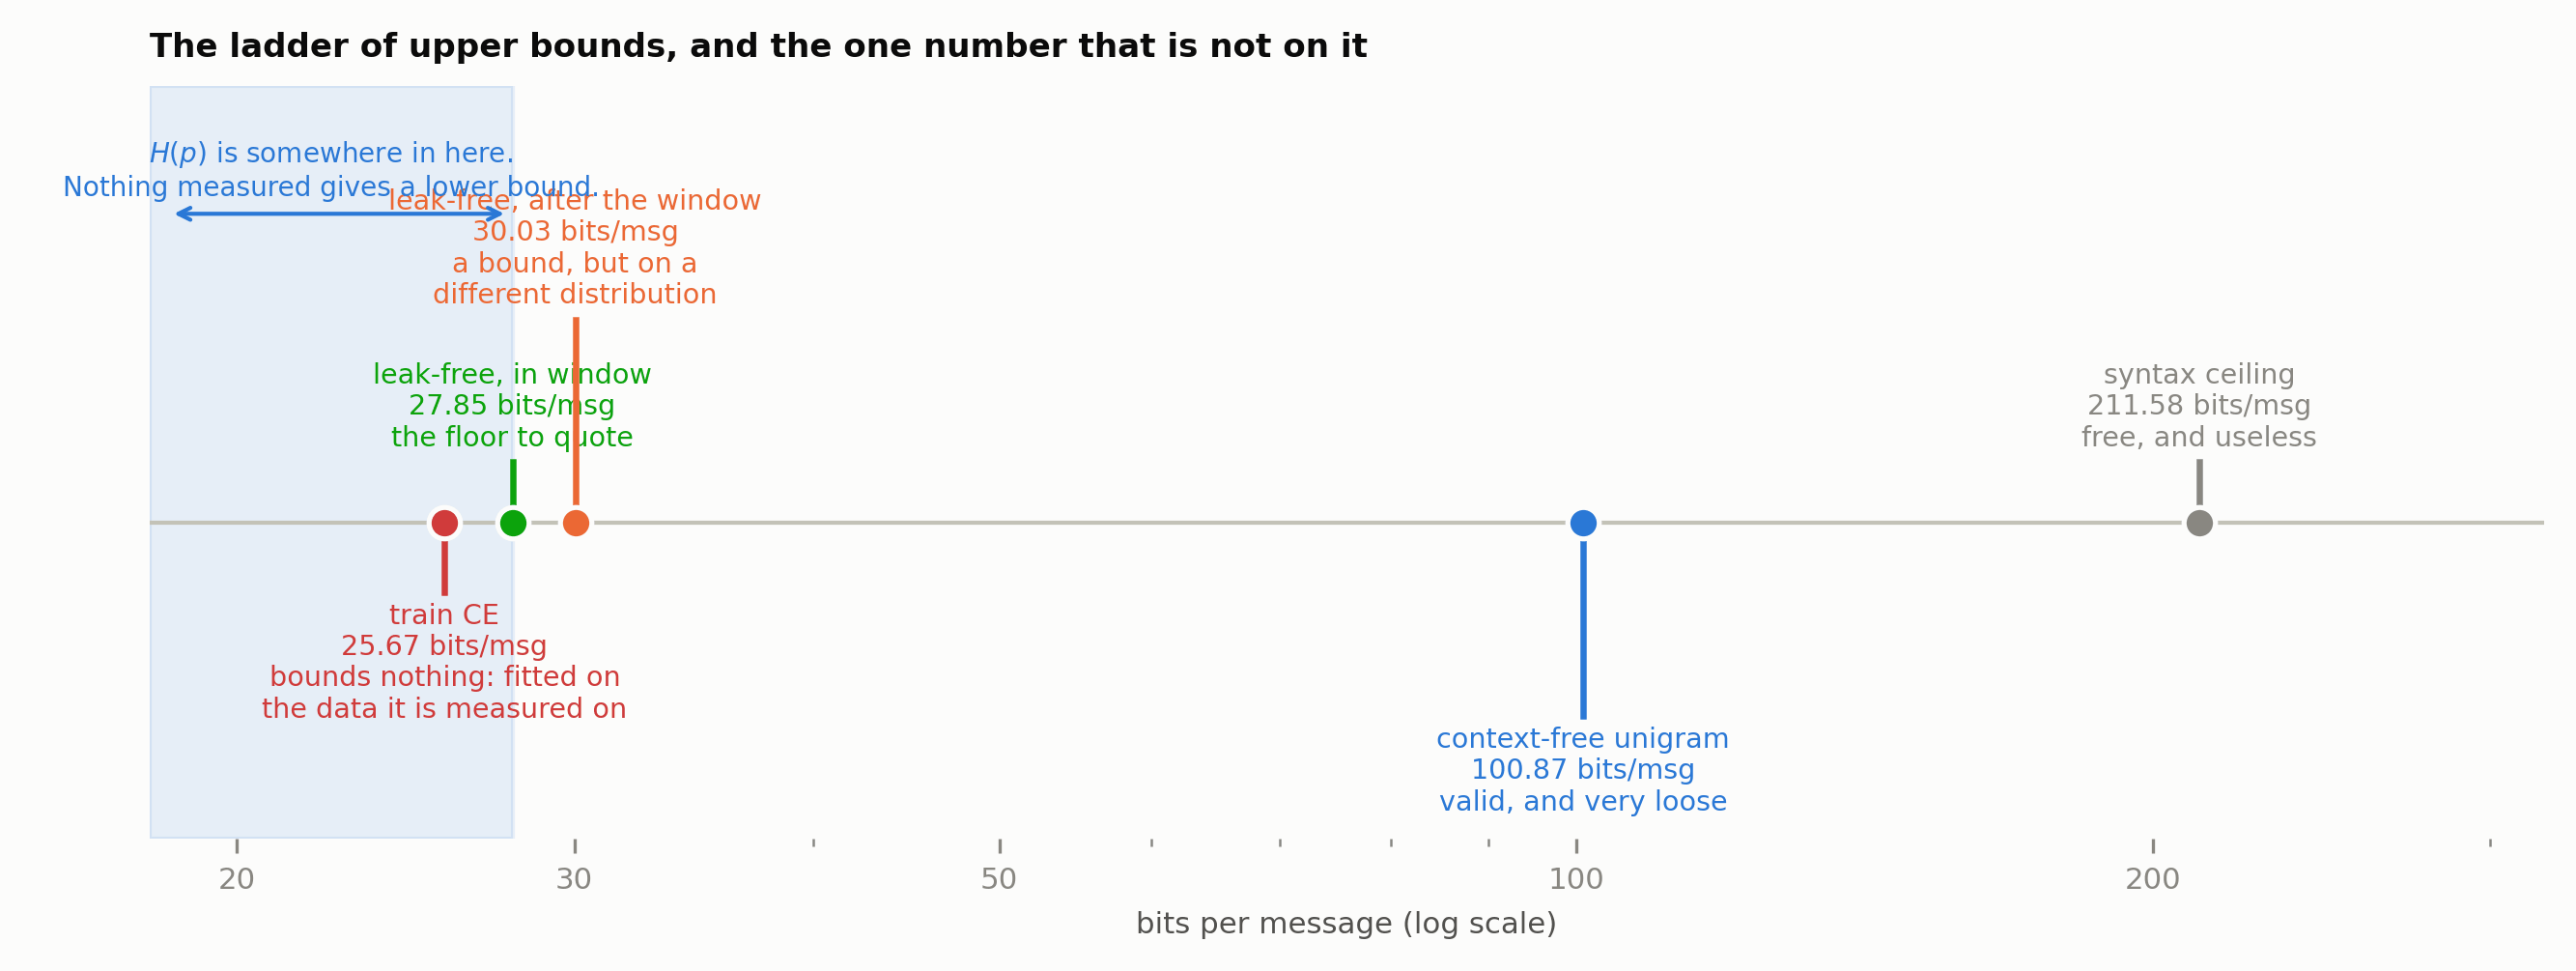

train CE                    25.67 bits/msg   no inequality relates this to H(p)
leak-free, in window        27.85             = H(p) + KL >= H(p), same distribution
leak-free, after window     30.03             = H(p') + KL, a different p'
context-free unigram       100.87             no model at all
syntax ceiling             211.58             ln(#valid) per position

train understates the in-window floor by 2.18 bits/msg;
the after-window slice overstates it by  2.19 bits/msg


In [2]:
uni_bits = pos.unigram_nats.clip(lower=0).sum() / LN2
ceil_bits = pos.ceiling_nats.sum() / LN2

fig, ax = plt.subplots(figsize=(8.89, 3.35))
XLO, XHI = 18.0, 320.0
ax.axhline(0, color=AXIS, lw=1.01, zorder=2)
ax.axvspan(XLO, BITS_VA, color=BLUE, alpha=0.10, zorder=0)

marks = [
    (BITS_TR, "train CE", CRIT, "bounds nothing: fitted on\nthe data it is measured on", -1, 0.34),
    (BITS_VA, "leak-free, in window", GOOD, "the floor to quote", +1, 0.30),
    (BITS_HO, "leak-free, after the window", ORANGE, "a bound, but on a\ndifferent distribution", +1, 1.00),
    (uni_bits, "context-free unigram", BLUE, "valid, and very loose", -1, 0.95),
    (ceil_bits, "syntax ceiling", MUTED, "free, and useless", +1, 0.30),
]
for x, name, col, note, side, stem in marks:
    ax.plot([x, x], [0, side * stem], color=col, lw=1.56, zorder=3)
    ax.plot(x, 0, "o", ms=7.80, mfc=col, mec=SURFACE, mew=1.25, zorder=4)
    ax.annotate(f"{name}\n{x:.2f} bits/msg\n{note}", (x, side * (stem + 0.05)), fontsize=6.86,
                color=col, ha="center", va="bottom" if side > 0 else "top")
ax.annotate("", (XLO * 1.02, 1.52), (BITS_VA, 1.52),
            arrowprops=dict(arrowstyle="<->", color=BLUE, lw=1.01))
ax.annotate("$H(p)$ is somewhere in here.\nNothing measured gives a lower bound.",
            (math.sqrt(XLO * BITS_VA), 1.58), fontsize=6.71, color=BLUE, ha="center", va="bottom")
ax.set_xscale("log"); ax.set_xlim(XLO, XHI); ax.set_ylim(-1.55, 2.15)
ax.set_xticks([20, 30, 50, 100, 200], ["20", "30", "50", "100", "200"])
ax.set_yticks([]); ax.grid(False)
ax.spines["left"].set_visible(False); ax.spines["bottom"].set_visible(False)
tidy(ax, "bits per message (log scale)", None,
     "The ladder of upper bounds, and the one number that is not on it")
fig.tight_layout(); show(fig)

print(f"train CE                  {BITS_TR:7.2f} bits/msg   no inequality relates this to H(p)")
print(f"leak-free, in window      {BITS_VA:7.2f}             = H(p) + KL >= H(p), same distribution")
print(f"leak-free, after window   {BITS_HO:7.2f}             = H(p') + KL, a different p'")
print(f"context-free unigram      {uni_bits:7.2f}             no model at all")
print(f"syntax ceiling            {ceil_bits:7.2f}             ln(#valid) per position")
print(f"\ntrain understates the in-window floor by {BITS_VA - BITS_TR:.2f} bits/msg;")
print(f"the after-window slice overstates it by  {BITS_HO - BITS_VA:.2f} bits/msg")

*The training number understates the in-window floor by 2.18 bits/msg and the
after-the-window number overstates it by 2.19, so the two readings the first pass had
available bracket the answer almost symmetrically and neither is it.*

## Figure 2 - the gap, split two ways

Inserting a leak-free in-window slice turns the first pass's single number into two steps.
But the first step is measured across a period gap as well as a leakage one: A is December
and C is the January-November mean. Both readings are drawn here, and Figure 3 says which
to believe without relying on the extrapolation behind the second.

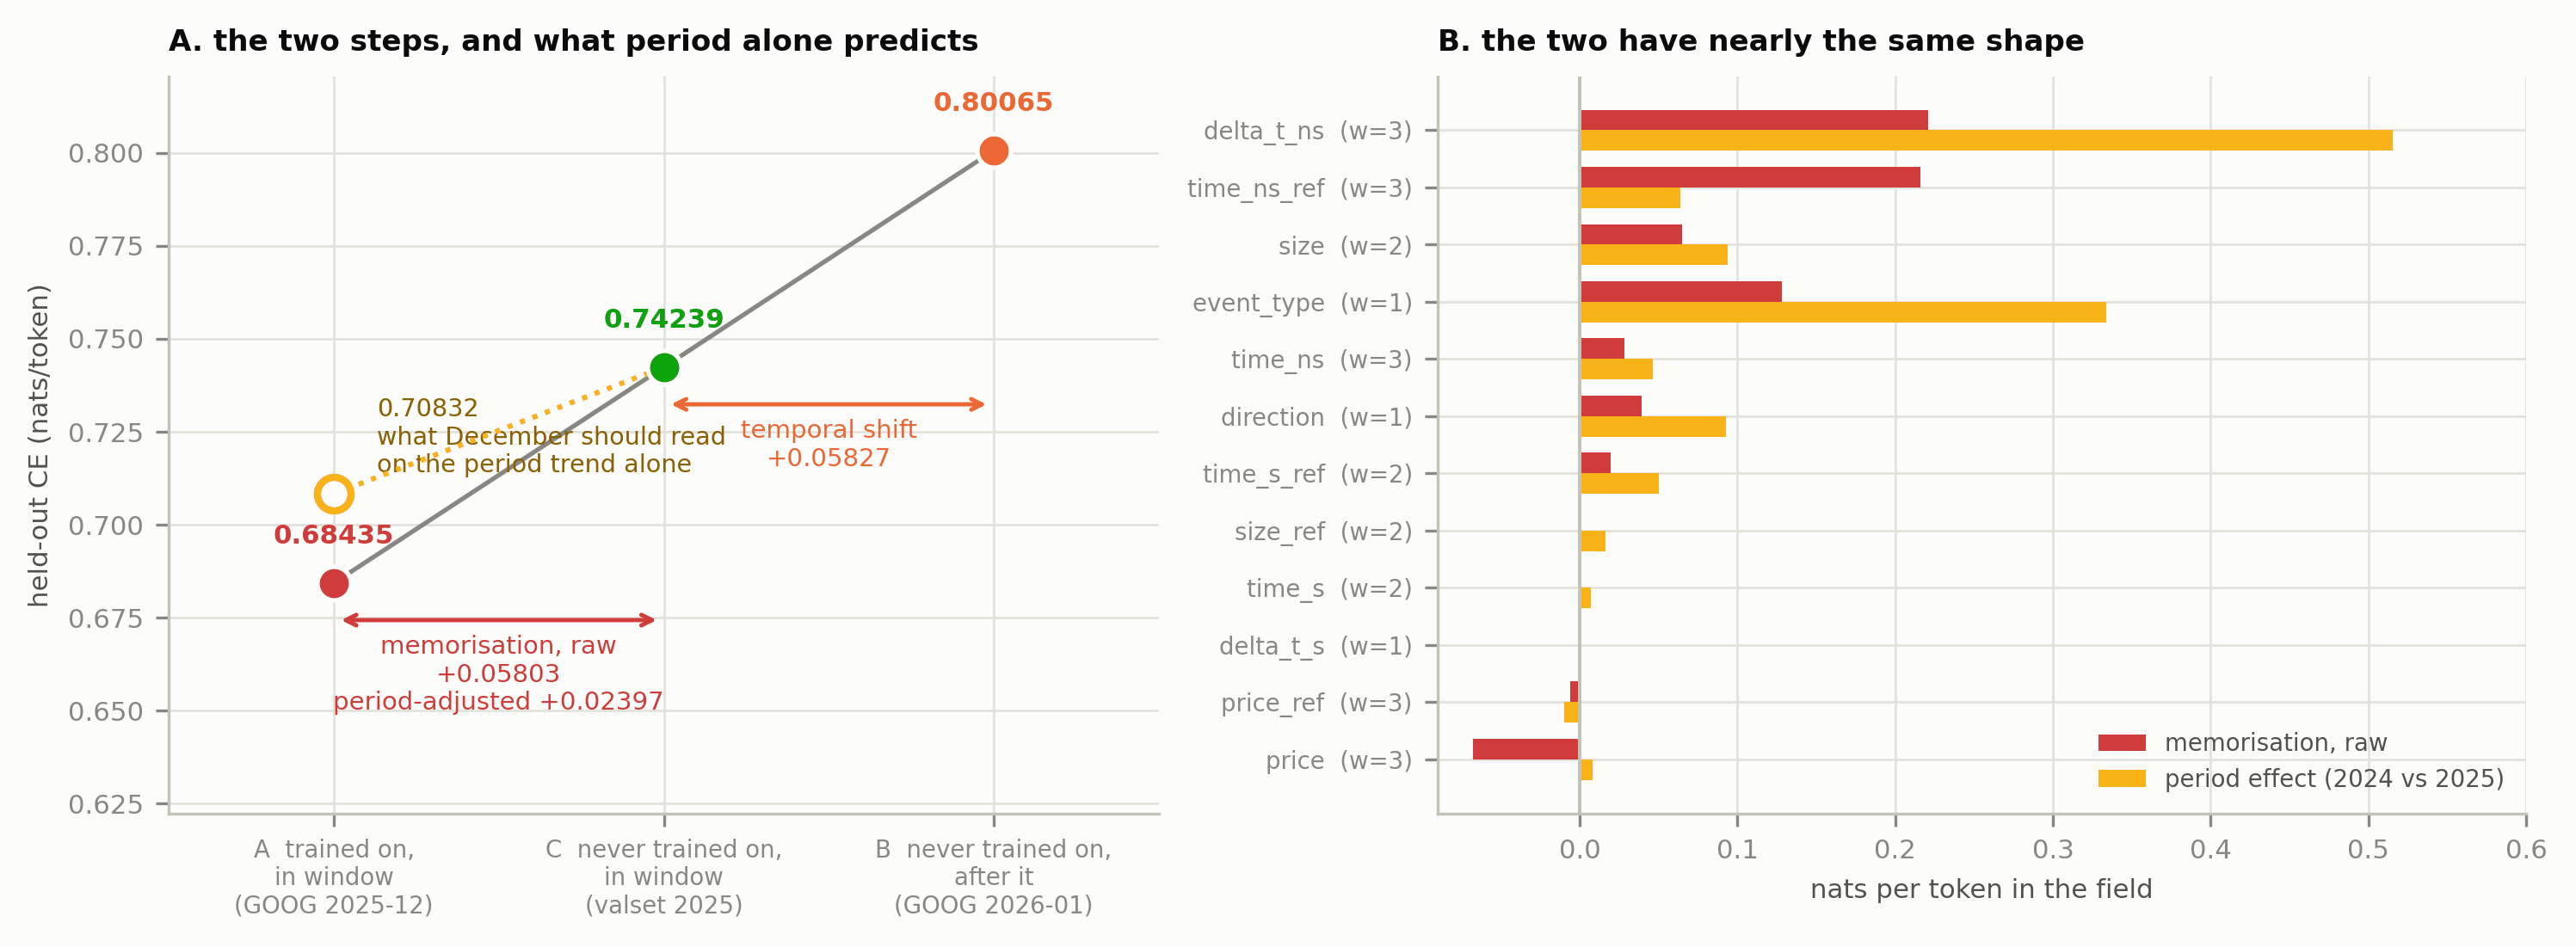

      field  width  train  valset   held  memorisation  tshift  period_year
 delta_t_ns      3 2.8447  3.0654 3.2461        0.2207  0.1807       0.5152
time_ns_ref      3 1.4856  1.7013 1.7692        0.2157  0.0679       0.0639
 event_type      1 0.5913  0.7197 0.7191        0.1283 -0.0006       0.3340
       size      2 0.4210  0.4859 0.5135        0.0649  0.0276       0.0937
  direction      1 0.3241  0.3635 0.3830        0.0395  0.0194       0.0928
    time_ns      3 0.1213  0.1495 0.1558        0.0282  0.0063       0.0461
 time_s_ref      2 0.1672  0.1866 0.1996        0.0194  0.0130       0.0503
   size_ref      2 0.0140  0.0144 0.0106        0.0005 -0.0039       0.0162
     time_s      2 0.0163  0.0164 0.0147        0.0001 -0.0017       0.0073
  delta_t_s      1 0.0007  0.0001 0.0003       -0.0006  0.0002       0.0010
  price_ref      3 0.1344  0.1283 0.1690       -0.0061  0.0407      -0.0100
      price      3 0.6273  0.5594 0.7392       -0.0679  0.1797       0.0083


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9.98, 3.67), gridspec_kw={"width_ratios": [1, 1.1]})

ax = axes[0]
xs, ys = [0, 1, 2], [CE_TR, CE_VA, CE_HO]
names = ["A  trained on,\nin window\n(GOOG 2025-12)",
         "C  never trained on,\nin window\n(valset 2025)",
         "B  never trained on,\nafter it\n(GOOG 2026-01)"]
for x, y, c in zip(xs, ys, [CRIT, GOOD, ORANGE]):
    ax.plot(x, y, "o", ms=9.36, mfc=c, mec=SURFACE, mew=1.25, zorder=4)
    ax.annotate(f"{y:.5f}", (x, y), xytext=(0, 11), textcoords="offset points",
                fontsize=7.41, color=c, ha="center", weight="bold")
ax.plot(xs, ys, "-", color=MUTED, lw=1.25, zorder=2)
if DEC_EXPECTED:
    ax.plot(0, DEC_EXPECTED, "o", ms=9.36, mfc=SURFACE, mec=WARN, mew=2.0, zorder=5)
    ax.annotate(f"{DEC_EXPECTED:.5f}\nwhat December should read\non the period trend alone",
                (0, DEC_EXPECTED), xytext=(12, 6), textcoords="offset points",
                fontsize=6.86, color="#8a6200", ha="left")
    ax.plot([0, 1], [DEC_EXPECTED, CE_VA], ":", color=WARN, lw=1.4, zorder=3)
ax.annotate("", (0, CE_TR - 0.010), (1, CE_TR - 0.010),
            arrowprops=dict(arrowstyle="<->", color=CRIT, lw=1.17))
ax.annotate(f"memorisation, raw\n{MEM:+.5f}" +
            (f"\nperiod-adjusted {MEM_ADJ:+.5f}" if MEM_ADJ else ""),
            (0.5, CE_TR - 0.014), fontsize=7.02, color=CRIT, ha="center", va="top")
ax.annotate("", (1, CE_VA - 0.010), (2, CE_VA - 0.010),
            arrowprops=dict(arrowstyle="<->", color=ORANGE, lw=1.17))
ax.annotate(f"temporal shift\n{SHIFT:+.5f}", (1.5, CE_VA - 0.014), fontsize=7.02,
            color=ORANGE, ha="center", va="top")
ax.set_xticks(xs, names, fontsize=6.63)
ax.set_xlim(-0.5, 2.5); ax.set_ylim(CE_TR - 0.062, CE_HO + 0.020)
tidy(ax, None, "held-out CE (nats/token)", "A. the two steps, and what period alone predicts")

ax = axes[1]
f2 = fld.sort_values("mem_share", ascending=False).reset_index(drop=True)
y = np.arange(len(f2)); h = 0.36
ax.barh(y - h / 2, f2.memorisation, height=h, color=CRIT, zorder=3, label="memorisation, raw")
if "period_year" in f2:
    ax.barh(y + h / 2, f2.period_year, height=h, color=WARN, zorder=3,
            label="period effect (2024 vs 2025)")
ax.axvline(0, color=AXIS, lw=0.94, zorder=4)
ax.set_yticks(y, [f"{r.field}  (w={int(r.width)})" for _, r in f2.iterrows()], fontsize=6.63)
ax.invert_yaxis(); ax.set_xlim(-0.09, 0.60)
ax.legend(loc="lower right", fontsize=6.63, labelcolor=INK2)
tidy(ax, "nats per token in the field", None, "B. the two have nearly the same shape")
fig.tight_layout(); show(fig)

cols = ["field", "width", "train", "valset", "held", "memorisation", "tshift"]
if "period_year" in fld: cols += ["period_year"]
print(fld[cols].sort_values("memorisation", ascending=False).round(4).to_string(index=False))

*The raw split is 50/50 and the period-adjusted one is 21/79, and panel B is the reason to
distrust the first: the memorisation term and the period effect have nearly the same shape
across fields, which is what it looks like when most of the first is the second.*

## Figure 3 - is the in-sample advantage memory, or is it the calendar?

The adjustment in Figure 2 leans on a two-point slope pushed 3.5 months past its support,
so it cannot carry the conclusion by itself. This does not need it. If the in-sample
advantage were memory it would be unrelated to how much the period alone moves each field;
if it were period leaking into the measurement, the two would line up.

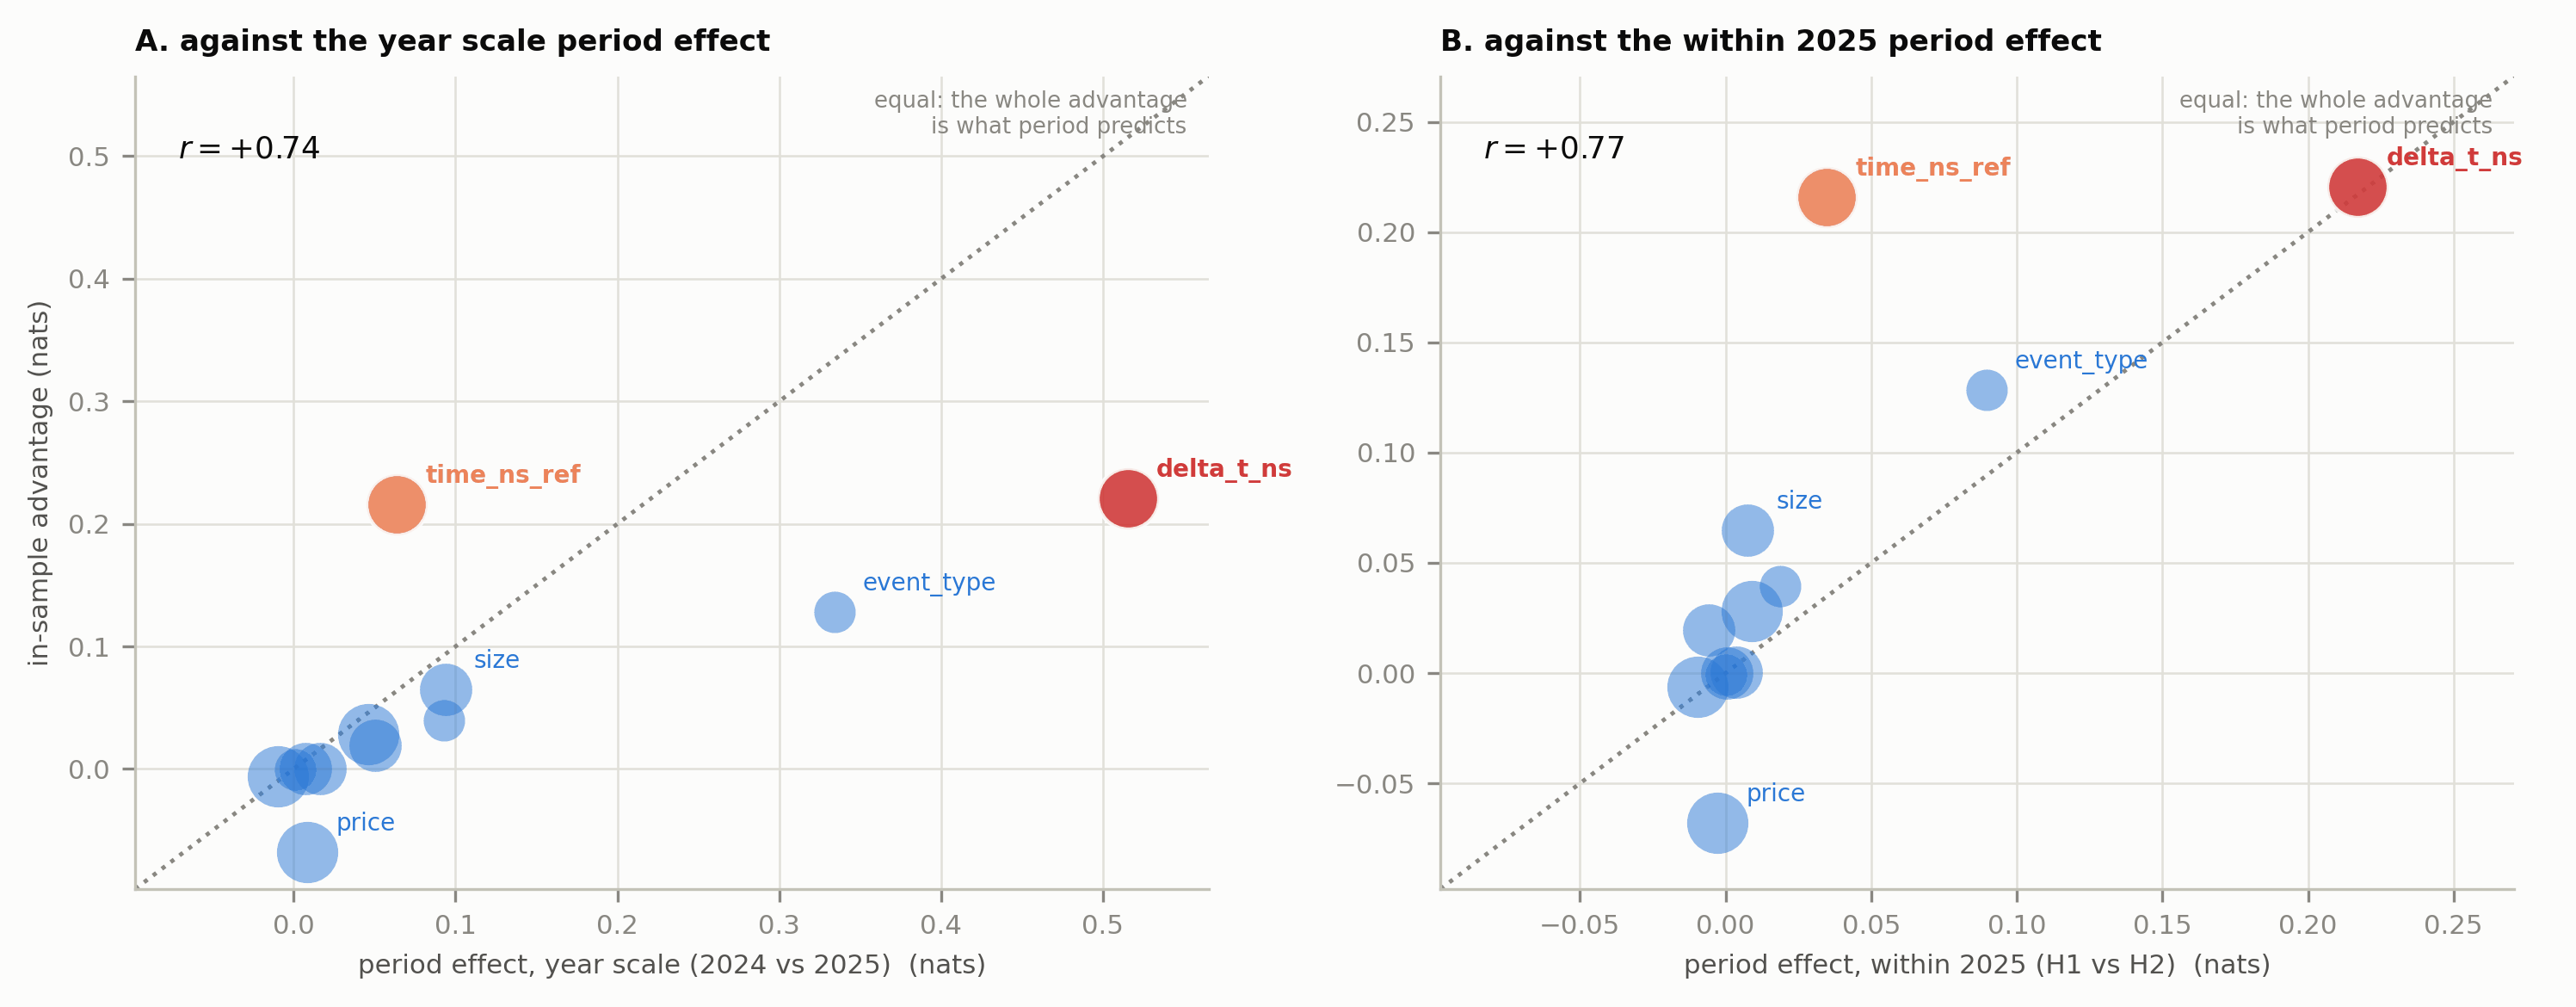

corr(in-sample advantage, year period effect) = +0.739
corr(in-sample advantage, within-2025 period effect) = +0.767

field          advantage  period(yr)   ratio
delta_t_ns       +0.2207     +0.5152    0.43
time_ns_ref      +0.2157     +0.0639    3.38
event_type       +0.1283     +0.3340    0.38
size             +0.0649     +0.0937    0.69
direction        +0.0395     +0.0928    0.43
time_ns          +0.0282     +0.0461    0.61


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9.98, 3.90))
for ax, col, lab in zip(axes, ["period_year", "period_within"],
                        ["year scale (2024 vs 2025)", "within 2025 (H1 vs H2)"]):
    if col not in fld:
        ax.axis("off"); continue
    r = fld[["memorisation", col]].corr().iloc[0, 1]
    lo = min(fld[col].min(), fld.memorisation.min()) - 0.03
    hi = max(fld[col].max(), fld.memorisation.max()) + 0.05
    ax.plot([lo, hi], [lo, hi], ls=":", color=MUTED, lw=1.17, zorder=2)
    ax.annotate("equal: the whole advantage\nis what period predicts", (hi, hi),
                xytext=(-6, -16), textcoords="offset points", fontsize=6.24,
                color=MUTED, ha="right")
    for _, q in fld.iterrows():
        flag = q.field in ("delta_t_ns", "time_ns_ref")
        c = SERIOUS if q.field == "time_ns_ref" else (CRIT if q.field == "delta_t_ns" else BLUE)
        ax.scatter(q[col], q.memorisation, s=54.8 + 79.1 * q.width, color=c,
                   alpha=0.9 if flag else 0.5, lw=1.09 if flag else 0,
                   edgecolors=SURFACE, zorder=4)
        if flag or abs(q.memorisation) > 0.05:
            ax.annotate(q.field, (q[col], q.memorisation), xytext=(8, 6),
                        textcoords="offset points", fontsize=6.71, color=c,
                        weight="semibold" if flag else "normal")
    ax.annotate(f"$r = {r:+.2f}$", (0.04, 0.90), xycoords="axes fraction",
                fontsize=8.58, color=INK)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    tidy(ax, f"period effect, {lab}  (nats)",
         "in-sample advantage (nats)" if col == "period_year" else None,
         f"{'A' if col == 'period_year' else 'B'}. against the {lab.split(' (')[0]} period effect")
fig.tight_layout(); show(fig)

for col, lab in (("period_year", "year"), ("period_within", "within-2025")):
    if col in fld:
        r = fld[["memorisation", col]].corr().iloc[0, 1]
        print(f"corr(in-sample advantage, {lab} period effect) = {r:+.3f}")
print(f"\n{'field':13s} {'advantage':>10s} {'period(yr)':>11s} {'ratio':>7s}")
for _, q in fld.sort_values("memorisation", ascending=False).head(6).iterrows():
    ratio = q.memorisation / q.period_year if abs(q.period_year) > 1e-6 else float("nan")
    print(f"{q.field:13s} {q.memorisation:+10.4f} {q.period_year:+11.4f} {ratio:7.2f}")

*The in-sample advantage tracks the period effect at $r = +0.74$ and $+0.77$, so most of it
is the calendar rather than memory -- with one field off the line in the direction that
matters: `time_ns_ref` sits 3.4x above what period predicts for it, while `delta_t_ns`, the
field the irreducible-noise claim names, sits at 0.43x and needs no memory to explain.*

## Figure 4 - "the floor" is two different things wearing one number

The irreducible-noise claim names positions 10 and 25 together. Position 10 is the low
nanosecond digit of the inter-arrival time; position 25 is the low nanosecond digit of a
**reference** timestamp, which points at a message already in the context. Read on the
leak-free slice, they behave nothing alike.

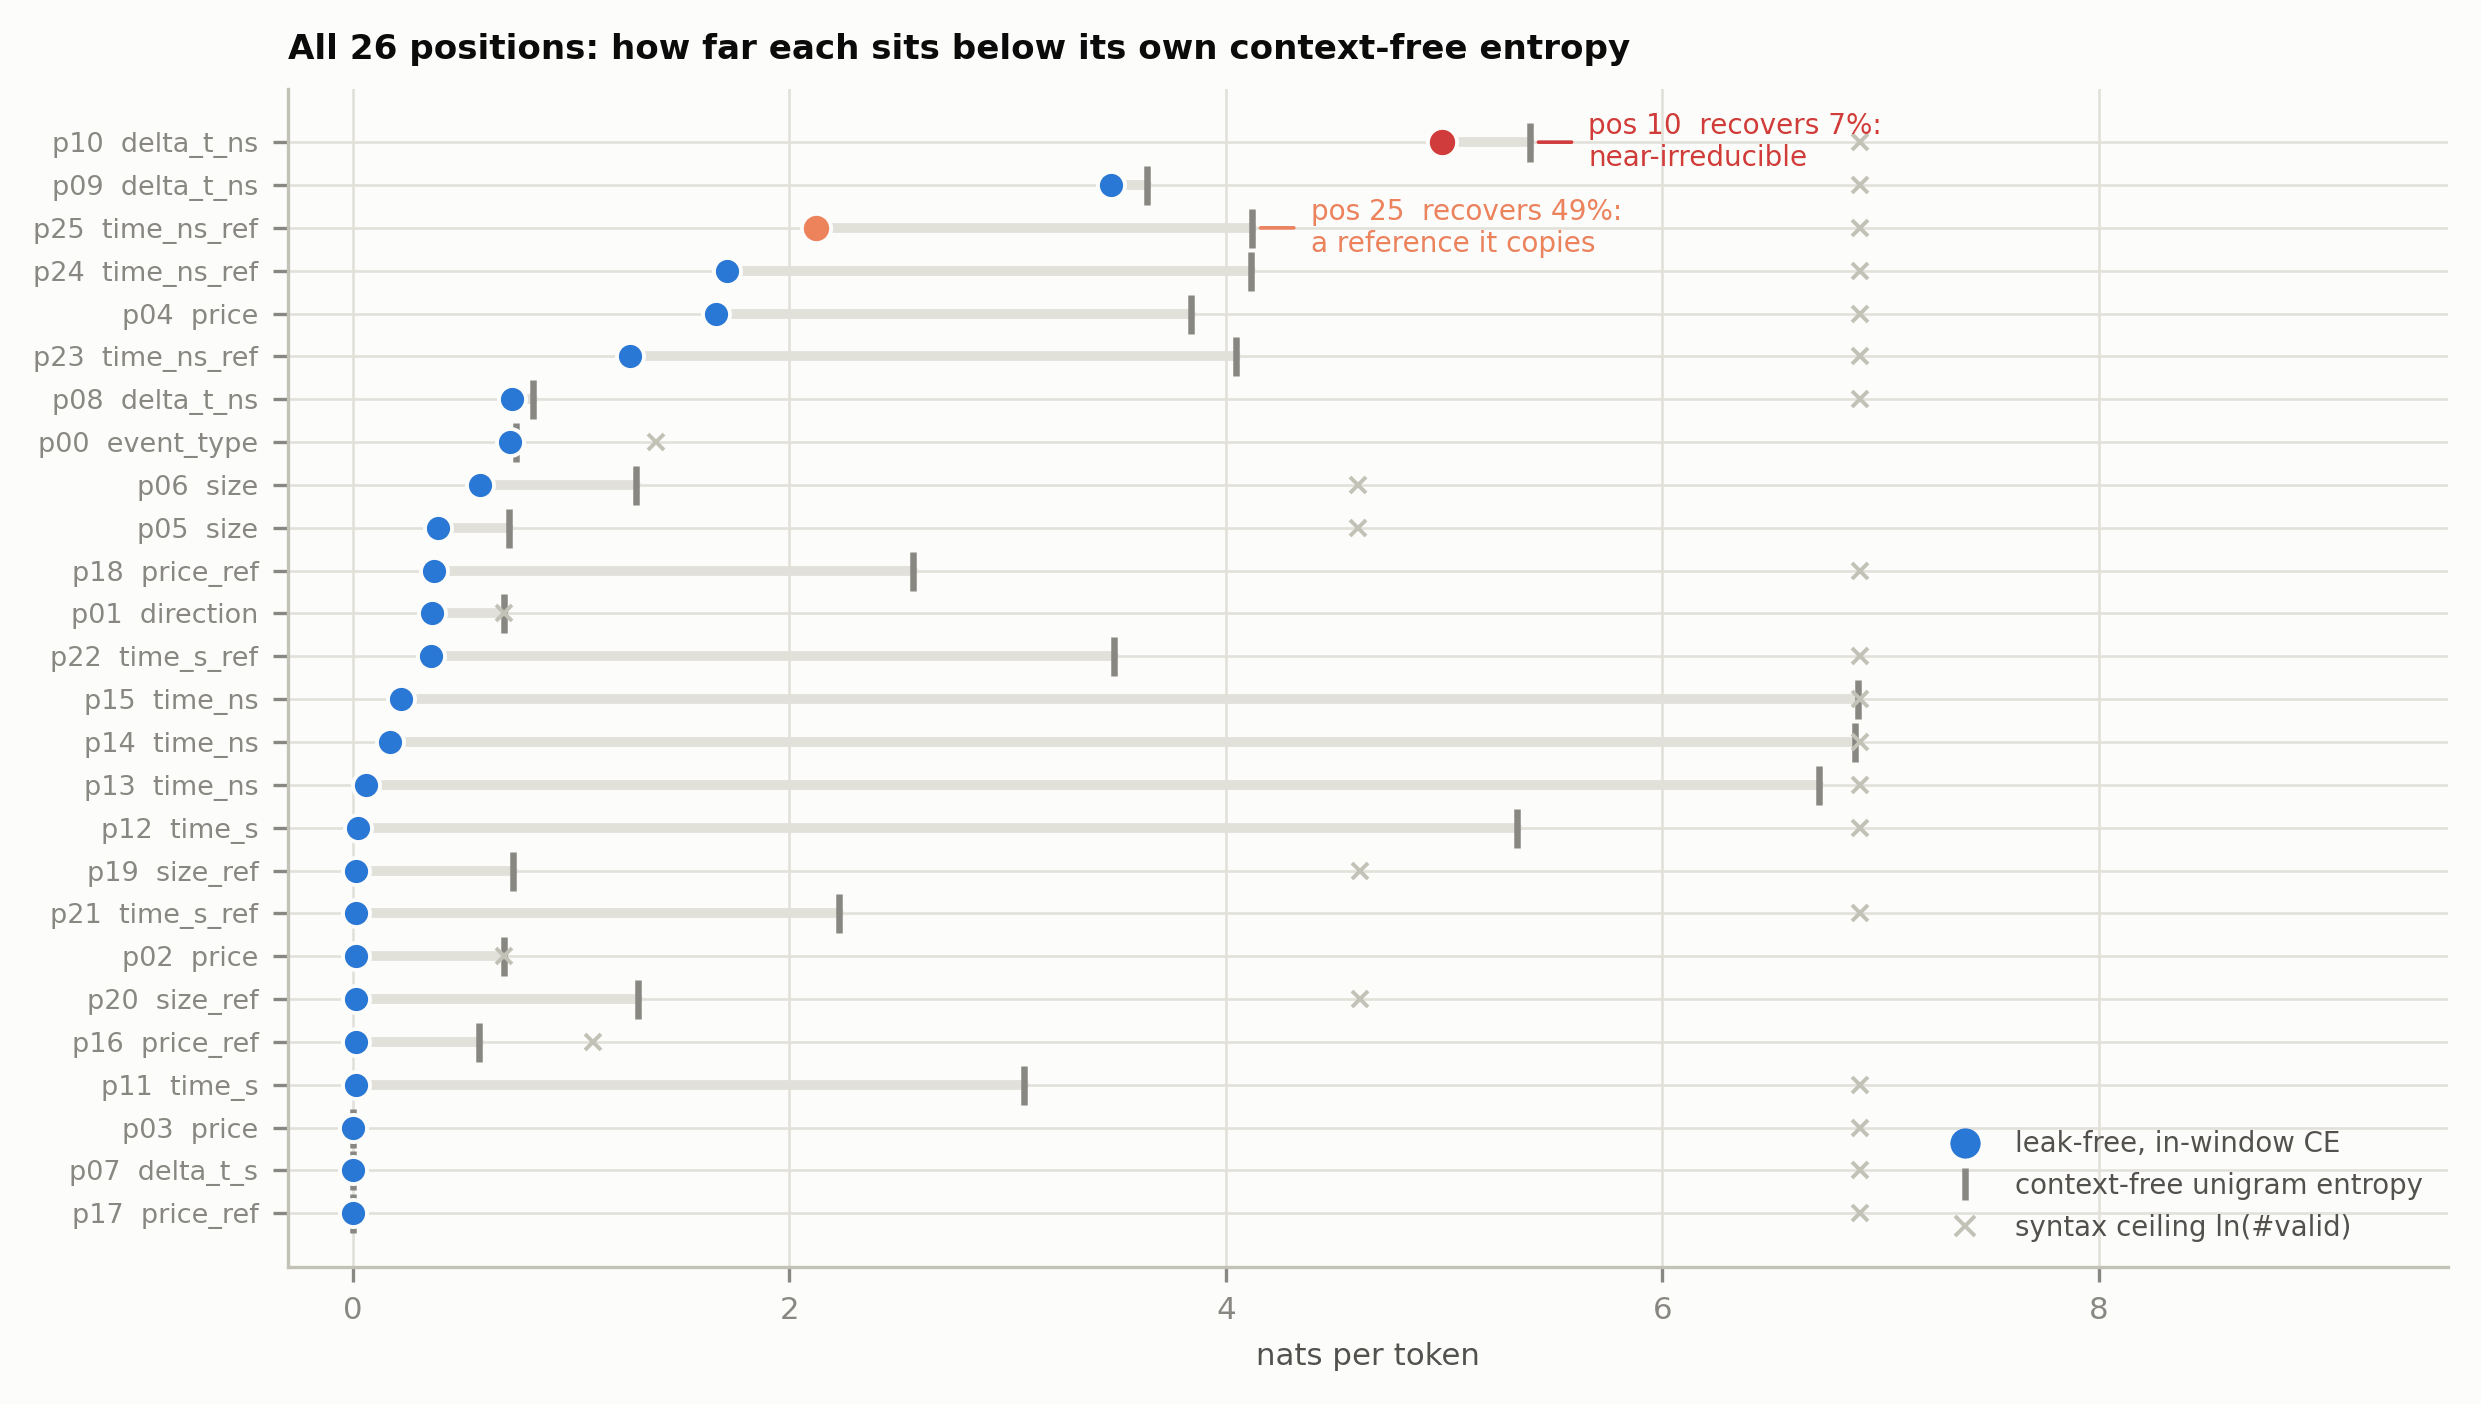

pos 10 delta_t_ns   leak-free 4.9908  train 4.7298  unigram 5.3941  recovered   7.5%  memorisation +0.2610  = 7.20 bits/msg
pos 25 time_ns_ref  leak-free 2.1211  train 1.8284  unigram 4.1209  recovered  48.5%  memorisation +0.2927  = 3.06 bits/msg

pos 10 alone : 7.20 bits/msg leak-free (6.82 on train)
pos 10 + 25  : 10.26 bits/msg leak-free (9.46 on train)
cited claim  : 7.57 bits/msg for 'positions 10 and 25'


In [5]:
order = pos.sort_values("valset", ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8.27, 4.68))
y = np.arange(len(order))
for i, r in order.iterrows():
    ax.plot([r.valset, max(r.unigram_nats, 0)], [i, i], color=GRID, lw=2.34,
            solid_capstyle="round", zorder=2)
    ax.plot(max(r.unigram_nats, 0), i, "|", ms=9.36, color=MUTED, mew=1.56, zorder=3)
    flag = r.position in (10, 25)
    col = CRIT if r.position == 10 else (SERIOUS if r.position == 25 else BLUE)
    ax.plot(r.valset, i, "o", ms=7.02 if flag else 6.5, mfc=col, mec=SURFACE, mew=0.94, zorder=4)
    ax.plot(r.ceiling_nats, i, "x", ms=3.90, color=AXIS, mew=0.94, zorder=3)
ax.set_yticks(y, [f"p{int(r.position):02d}  {r.field}" for _, r in order.iterrows()], fontsize=6.47)
ax.invert_yaxis(); ax.set_xlim(-0.3, 9.6)
for p_id, col in ((10, CRIT), (25, SERIOUS)):
    i = int(order.index[order.position == p_id][0]); r = order.loc[i]
    rec = 100 * (r.unigram_nats - r.valset) / r.unigram_nats
    ax.annotate(f"pos {p_id}  recovers {rec:.0f}%:\n"
                f"{'near-irreducible' if rec < 20 else 'a reference it copies'}",
                (max(r.unigram_nats, 0), i), xytext=(14, 0), textcoords="offset points",
                fontsize=6.71, color=col, va="center",
                arrowprops=dict(arrowstyle="-", color=col, lw=0.86))
ax.legend(handles=[Line2D([], [], marker="o", ls="", ms=6.24, color=BLUE,
                          label="leak-free, in-window CE"),
                   Line2D([], [], marker="|", ls="", ms=7.80, mew=1.56, color=MUTED,
                          label="context-free unigram entropy"),
                   Line2D([], [], marker="x", ls="", ms=4.68, mew=0.94, color=AXIS,
                          label="syntax ceiling ln(#valid)")],
          loc="lower right", fontsize=6.63, labelcolor=INK2)
tidy(ax, "nats per token", None,
     "All 26 positions: how far each sits below its own context-free entropy")
fig.tight_layout(); show(fig)

p10, p25 = [pos[pos.position == i].iloc[0] for i in (10, 25)]
for r in (p10, p25):
    rec = 100 * (r.unigram_nats - r.valset) / r.unigram_nats
    print(f"pos {int(r.position):2d} {r.field:12s} leak-free {r.valset:.4f}  train {r.train:.4f}  "
          f"unigram {r.unigram_nats:.4f}  recovered {rec:5.1f}%  "
          f"memorisation {r.memorisation:+.4f}  = {r.valset/LN2:.2f} bits/msg")
print(f"\npos 10 alone : {p10.valset/LN2:.2f} bits/msg leak-free ({p10.train/LN2:.2f} on train)")
print(f"pos 10 + 25  : {(p10.valset+p25.valset)/LN2:.2f} bits/msg leak-free "
      f"({(p10.train+p25.train)/LN2:.2f} on train)")
print("cited claim  : 7.57 bits/msg for 'positions 10 and 25'")

*Position 10 removes 5% of its context-free entropy and position 25 removes 47%, so one is
close to irreducible and the other is a reference field the model has half solved, and the
cited 7.57 bits/msg matches neither of them on the leak-free slice.*

## Figure 5 - the period moves CE far more than either effect being measured

The precision slice raised this. Drawn over 2022-2025 the leak-free set reads 0.949
against 0.742 for 2025 alone -- so before the decomposition above can stand, the period
has to be measured on its own. Every slice here is leak-free and inside the training
window; only the period differs. The two halves of 2025 are the ones that matter: the
memorisation term is differenced across exactly that span, so their difference is the
contamination.

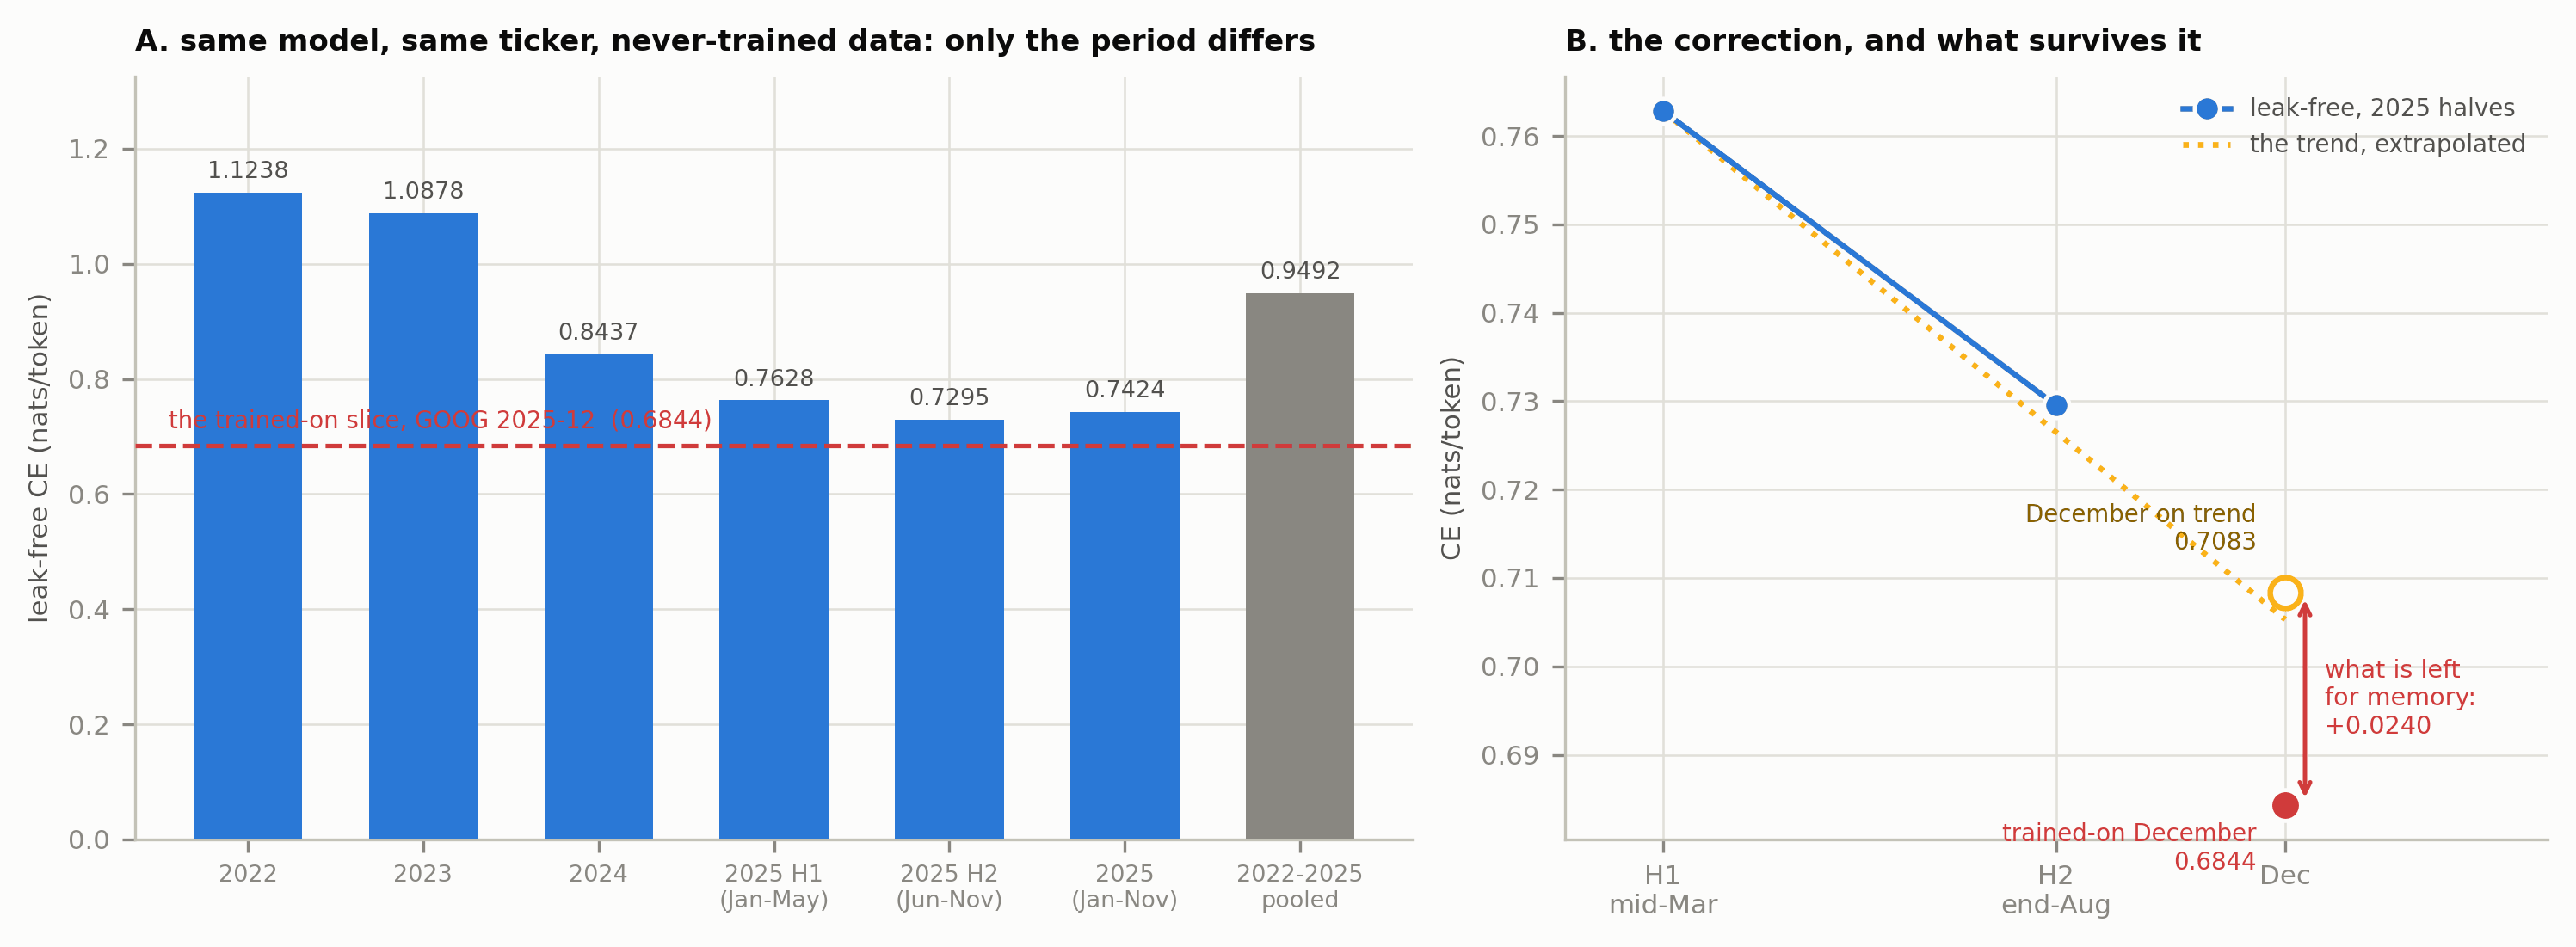

valset_2022      2022-01-01..2022-12-31    128 seq  CE 1.12379  vs 2025 +0.38141
valset_2023      2023-01-01..2023-12-31     96 seq  CE 1.08778  vs 2025 +0.34540
valset_2024      2024-01-01..2024-12-31    128 seq  CE 0.84366  vs 2025 +0.10127
valset_2025h1    2025-01-01..2025-05-31     64 seq  CE 0.76283  vs 2025 +0.02044
valset_2025h2    2025-06-01..2025-11-30     64 seq  CE 0.72952  vs 2025 -0.01287
valset_2025      2025-01-01..2025-11-30    128 seq  CE 0.74239  vs 2025 +0.00000
valset_all       2022-01-01..2025-11-30    512 seq  CE 0.94924  vs 2025 +0.20686

within 2025 (H2 - H1)  -0.03331 nats
memorisation term      +0.05803 nats  = 1.7x the within-2025 period spread


In [6]:
ORDER = ["valset_2022", "valset_2023", "valset_2024", "valset_2025h1", "valset_2025h2",
         "valset_2025", "valset_all"]
NICE = {"valset_2022": "2022", "valset_2023": "2023", "valset_2024": "2024",
        "valset_2025h1": "2025 H1\n(Jan-May)", "valset_2025h2": "2025 H2\n(Jun-Nov)",
        "valset_2025": "2025\n(Jan-Nov)", "valset_all": "2022-2025\npooled"}
avail = [(k, slice_(k)) for k in ORDER if slice_(k)]

fig, axes = plt.subplots(1, 2, figsize=(9.98, 3.67), gridspec_kw={"width_ratios": [1.3, 1]})

ax = axes[0]
xs = np.arange(len(avail))
ys = [v["aggregate"]["ce"] for _, v in avail]
cs = [MUTED if k == "valset_all" else BLUE for k, _ in avail]
ax.bar(xs, ys, width=0.62, color=cs, zorder=3)
ax.axhline(CE_TR, color=CRIT, lw=1.25, ls="--", zorder=4)
ax.annotate(f"the trained-on slice, GOOG 2025-12  ({CE_TR:.4f})", (-0.45, CE_TR),
            xytext=(0, 5), textcoords="offset points", fontsize=6.63, color=CRIT, ha="left")
for x, (k, v) in zip(xs, avail):
    ax.annotate(f"{v['aggregate']['ce']:.4f}", (x, v["aggregate"]["ce"]), xytext=(0, 4),
                textcoords="offset points", fontsize=6.47, color=INK2, ha="center")
ax.set_xticks(xs, [NICE[k] for k, _ in avail], fontsize=6.47)
ax.set_ylim(0, max(ys) * 1.18)
tidy(ax, None, "leak-free CE (nats/token)",
     "A. same model, same ticker, never-trained data: only the period differs")

ax = axes[1]
# The correction itself: where the within-2025 trend puts December, against what the
# trained-on slice actually reads there.
if DEC_EXPECTED:
    mx = [2.5, 8.5]                      # H1 and H2 midpoints, months into 2025
    ax.plot(mx, [E1, E2], "o-", color=BLUE, ms=7.02, mec=SURFACE, mew=1.17, zorder=4,
            label="leak-free, 2025 halves")
    xs_ = np.linspace(2.5, 12.0, 50)
    ax.plot(xs_, E1 + SLOPE * (xs_ - 2.5), ":", color=WARN, lw=1.56, zorder=3,
            label="the trend, extrapolated")
    ax.plot(12.0, DEC_EXPECTED, "o", ms=8.58, mfc=SURFACE, mec=WARN, mew=1.56, zorder=5)
    ax.annotate(f"December on trend\n{DEC_EXPECTED:.4f}", (12.0, DEC_EXPECTED),
                xytext=(-8, 12), textcoords="offset points", fontsize=6.63,
                color="#8a6200", ha="right")
    ax.plot(12.0, CE_TR, "o", ms=8.58, mfc=CRIT, mec=SURFACE, mew=1.17, zorder=5)
    ax.annotate(f"trained-on December\n{CE_TR:.4f}", (12.0, CE_TR), xytext=(-8, -18),
                textcoords="offset points", fontsize=6.63, color=CRIT, ha="right")
    ax.annotate("", (12.3, DEC_EXPECTED), (12.3, CE_TR),
                arrowprops=dict(arrowstyle="<->", color=CRIT, lw=1.17))
    ax.annotate(f"what is left\nfor memory:\n{MEM_ADJ:+.4f}", (12.6, (DEC_EXPECTED + CE_TR) / 2),
                fontsize=6.86, color=CRIT, va="center")
    ax.set_xlim(1, 16); ax.set_xticks([2.5, 8.5, 12], ["H1\nmid-Mar", "H2\nend-Aug", "Dec"])
    ax.legend(loc="upper right", fontsize=6.63, labelcolor=INK2)
tidy(ax, None, "CE (nats/token)", "B. the correction, and what survives it")
fig.tight_layout(); show(fig)

for k, v in avail:
    ce = v["aggregate"]["ce"]
    print(f"{k:16s} {'..'.join(v['slice']['date_range']):24s} {v['slice']['messages']//500:4d} seq  "
          f"CE {ce:.5f}  vs 2025 {ce - CE_VA:+.5f}")
if h1s and h2s:
    w = E2 - E1
    print(f"\nwithin 2025 (H2 - H1)  {w:+.5f} nats")
    print(f"memorisation term      {MEM:+.5f} nats  = {abs(MEM/w):.1f}x the within-2025 period spread"
          if abs(w) > 1e-9 else "")

*CE on never-trained data falls monotonically year over year and keeps falling inside 2025,
so December sits below the eleven-month mean on the calendar alone: extrapolating the
within-2025 slope leaves +0.024 of the raw +0.058 for memory, and that residual is 1.0
sigma.*

## Figure 6 - the 2x2, filled

The first pass had two of these four cells and could not name either effect. One of the
empty cells is impossible by construction; the other one is `valset_v1`, and it exists.

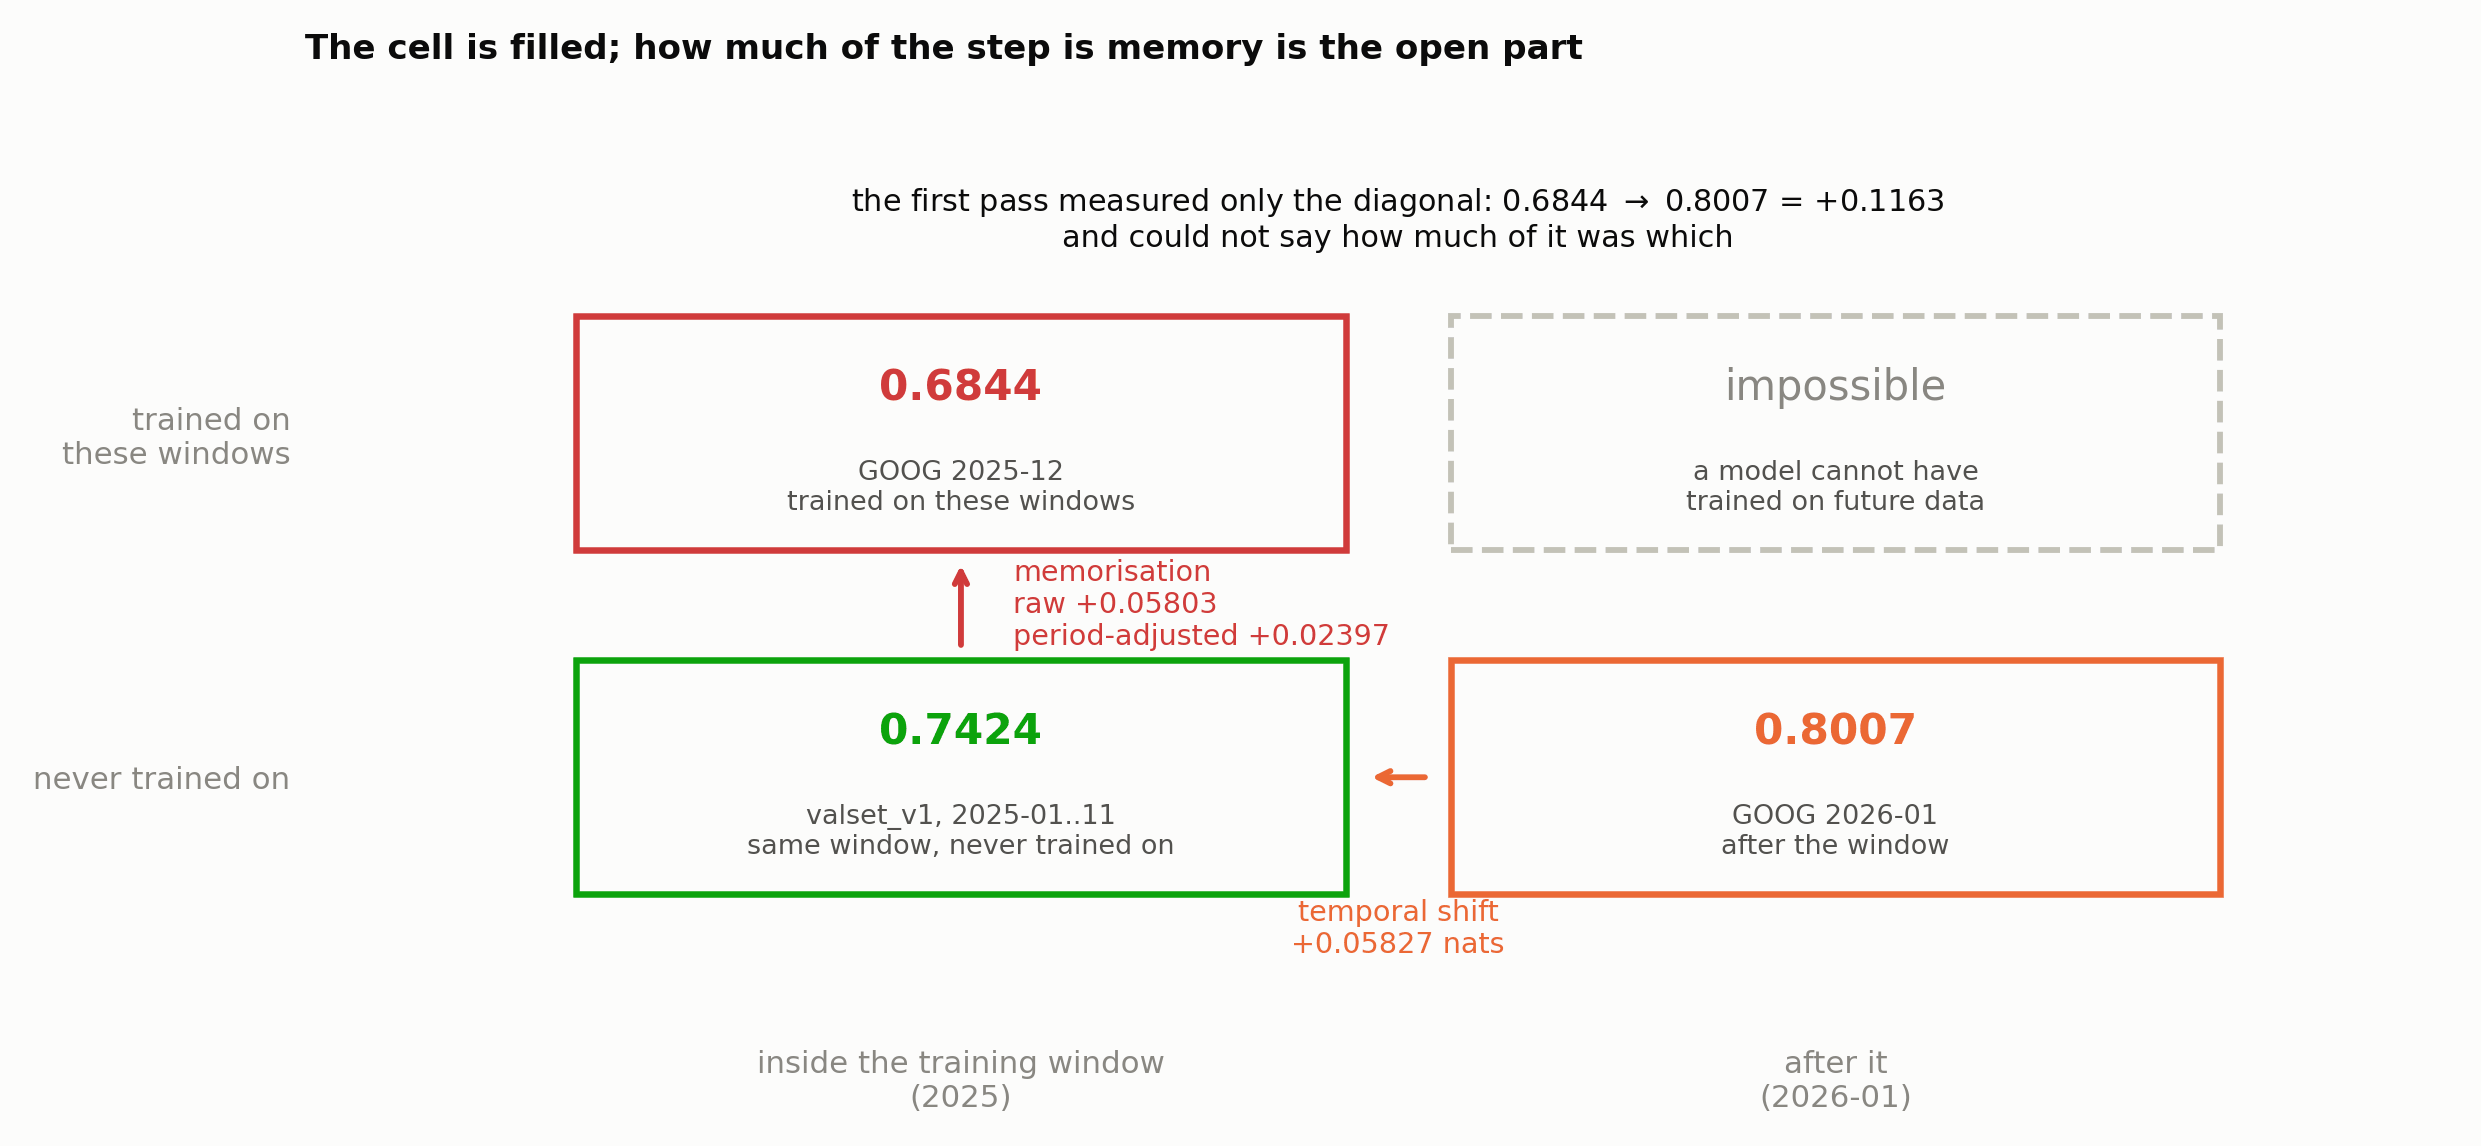

memorisation   +0.05803 nats = +2.18 bits/msg = 49.9% of A->B
temporal shift +0.05827 nats = +2.19 bits/msg = 50.1%


In [7]:
fig, ax = plt.subplots(figsize=(8.27, 3.82))
cells = {
    (0, 0): (f"{CE_TR:.4f}", "GOOG 2025-12\ntrained on these windows", CRIT, True),
    (1, 0): ("impossible", "a model cannot have\ntrained on future data", AXIS, False),
    (0, 1): (f"{CE_VA:.4f}", "valset_v1, 2025-01..11\nsame window, never trained on", GOOD, True),
    (1, 1): (f"{CE_HO:.4f}", "GOOG 2026-01\nafter the window", ORANGE, True),
}
for (col, row), (val, note, c, have) in cells.items():
    x, y = col * 1.0, -row * 1.0
    ax.add_patch(plt.Rectangle((x - 0.44, y - 0.34), 0.88, 0.68, facecolor=SURFACE,
                               edgecolor=c, lw=1.56 if have else 1.4,
                               linestyle="-" if have else "--", zorder=2))
    ax.annotate(val, (x, y + 0.13), fontsize=10.14 if have else 10, color=c if have else MUTED,
                ha="center", va="center", weight="bold" if have else "normal")
    ax.annotate(note, (x, y - 0.16), fontsize=6.47, color=INK2, ha="center", va="center")
ax.annotate("", (0.0, -0.36), (0.0, -0.64), arrowprops=dict(arrowstyle="->", color=CRIT, lw=1.40))
ax.annotate(f"memorisation\nraw {MEM:+.5f}" +
            (f"\nperiod-adjusted {MEM_ADJ:+.5f}" if MEM_ADJ else ""),
            (0.06, -0.5), fontsize=6.86, color=CRIT, ha="left", va="center")
ax.annotate("", (0.46, -1.0), (0.54, -1.0), arrowprops=dict(arrowstyle="->", color=ORANGE, lw=1.40))
ax.annotate(f"temporal shift\n{SHIFT:+.5f} nats", (0.5, -1.44), fontsize=6.86, color=ORANGE,
            ha="center", va="center")
ax.annotate(f"the first pass measured only the diagonal: {CE_TR:.4f} $\\rightarrow$ {CE_HO:.4f} "
            f"= {CE_HO - CE_TR:+.4f}\nand could not say how much of it was which",
            (0.5, 0.62), fontsize=7.25, color=INK, ha="center", va="center")
ax.set_xticks([0, 1], ["inside the training window\n(2025)", "after it\n(2026-01)"])
ax.set_yticks([0, -1], ["trained on\nthese windows", "never trained on"])
ax.set_xlim(-0.75, 1.7); ax.set_ylim(-1.75, 1.0); ax.grid(False)
for s_ in ("left", "bottom"): ax.spines[s_].set_visible(False)
ax.tick_params(length=0)
tidy(ax, None, None, "The cell is filled; how much of the step is memory is the open part")
fig.tight_layout(); show(fig)

print(f"memorisation   {MEM:+.5f} nats = {bits(MEM):+.2f} bits/msg = {100*MEM/(CE_HO-CE_TR):.1f}% of A->B")
print(f"temporal shift {SHIFT:+.5f} nats = {bits(SHIFT):+.2f} bits/msg = {100*SHIFT/(CE_HO-CE_TR):.1f}%")

*The missing cell is measured, but the vertical step still mixes memory with the calendar:
uncorrected it is half the difference the first pass reported, and corrected for the
within-2025 trend it is a fifth of it and no longer resolvable.*

## Figure 7 - what this sample size can resolve

`test_ce_eval_spec.md` line 42 fixes the budget: CE noise scales as $1/\sqrt{n}$ and
$\sigma(L) \le 0.002$ nats needs $n \gtrsim 5\times10^{7}$ tokens. The first pass ran 64
sequences, sixty times short. These slices run 128, which is still short but resolves more
of the field table.

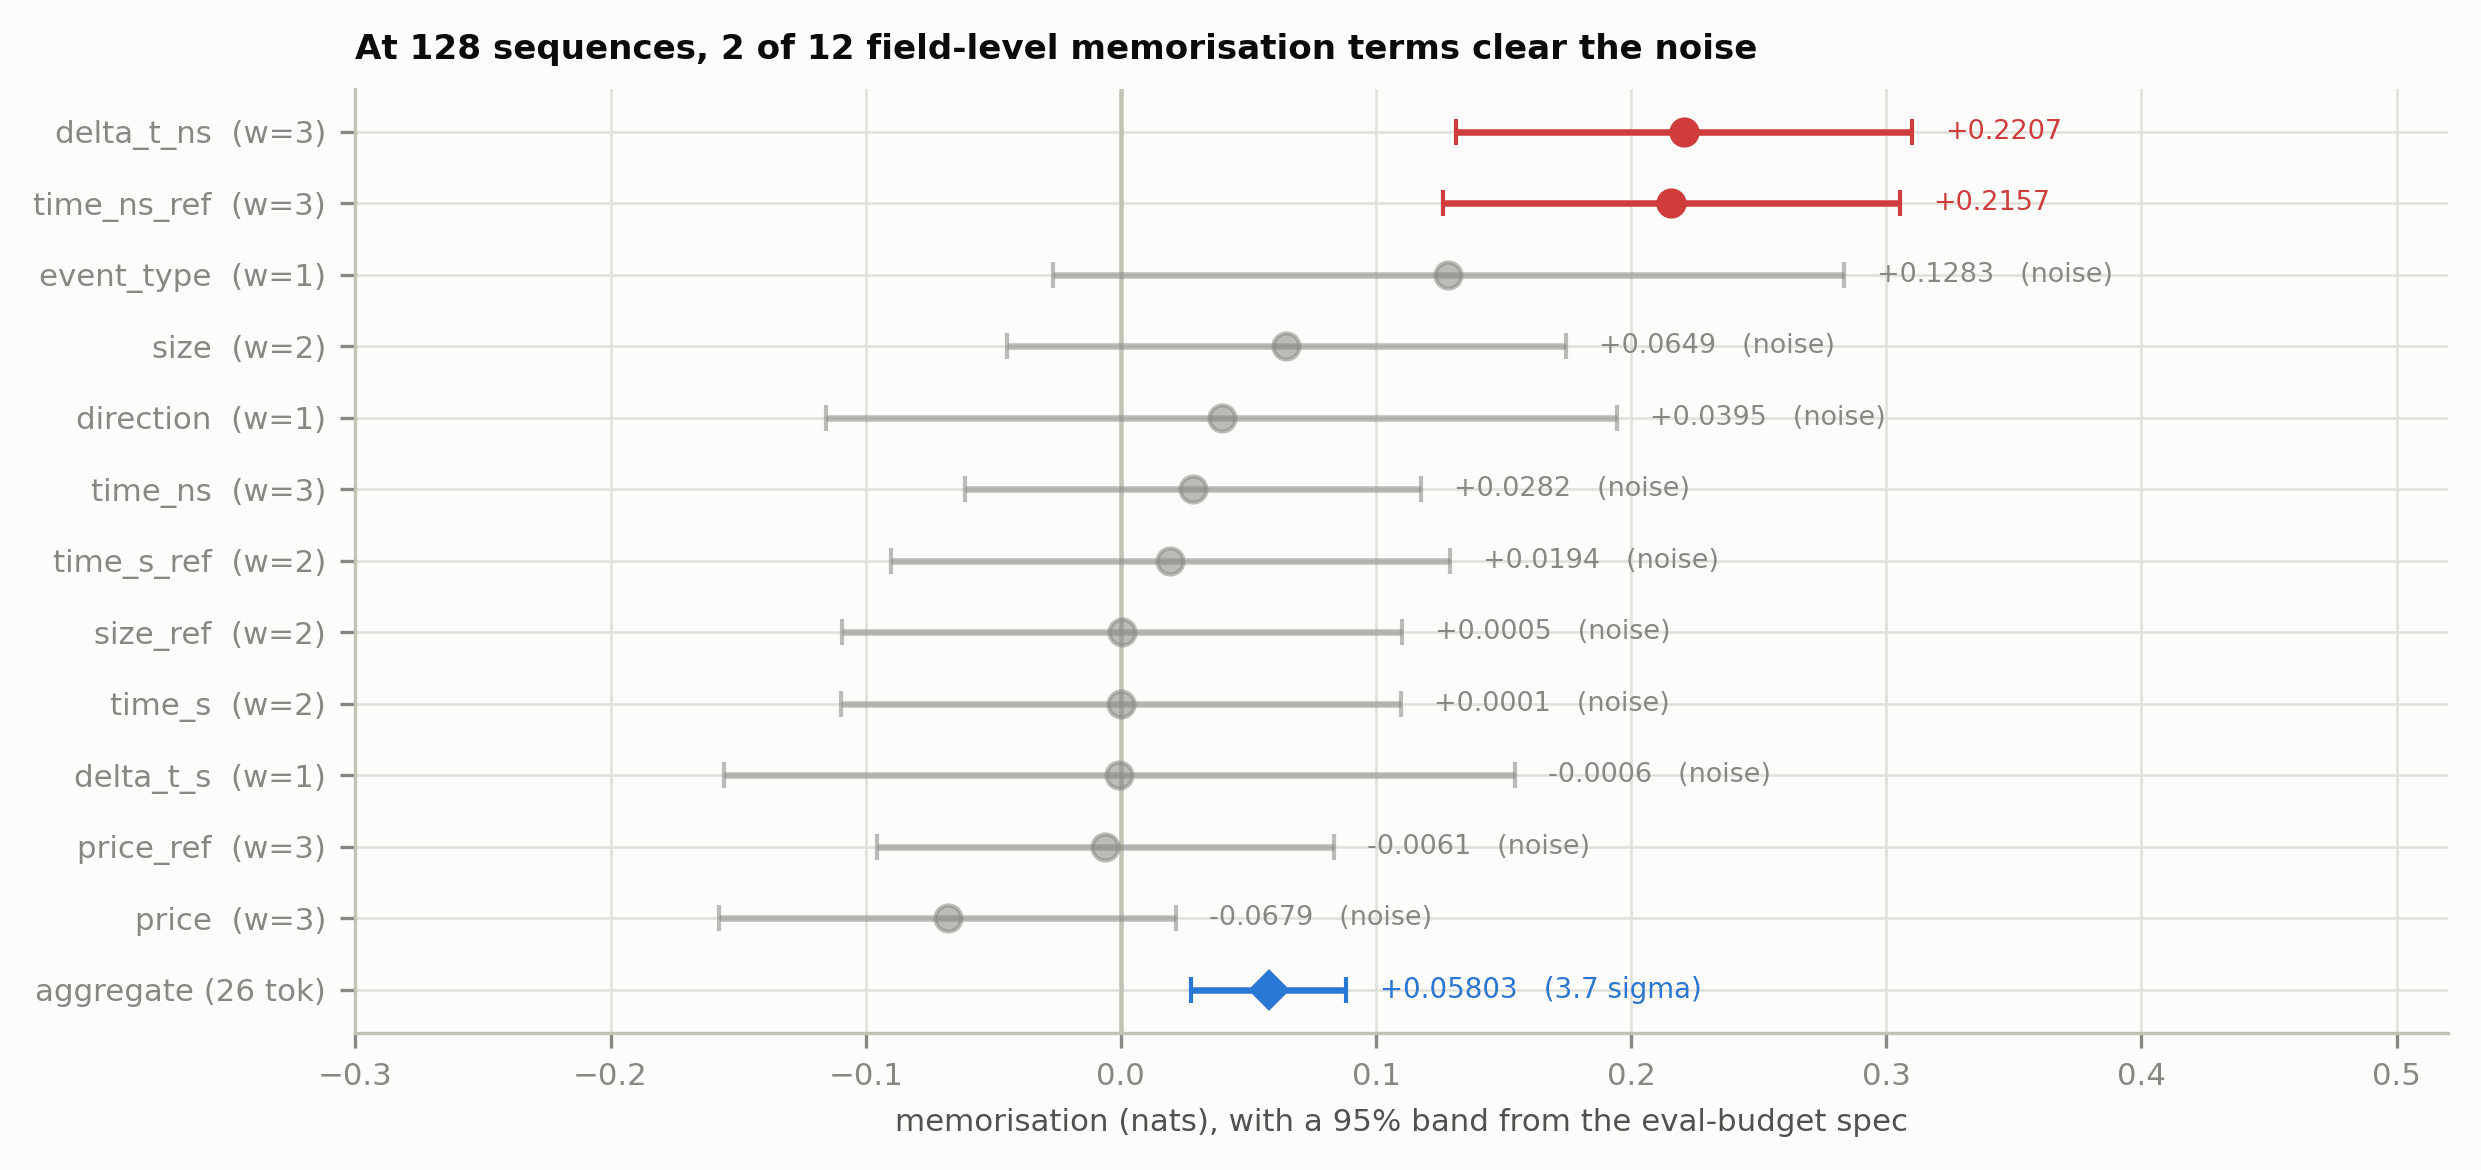

aggregate memorisation +0.05803, sigma 0.0155 -> 3.7 sigma
delta_t_ns   memorisation +0.2207  sigma 0.0456 ->  +4.8 sigma  RESOLVED
time_ns_ref  memorisation +0.2157  sigma 0.0456 ->  +4.7 sigma  RESOLVED
event_type   memorisation +0.1283  sigma 0.0791 ->  +1.6 sigma  noise
size         memorisation +0.0649  sigma 0.0559 ->  +1.2 sigma  noise
direction    memorisation +0.0395  sigma 0.0791 ->  +0.5 sigma  noise
time_ns      memorisation +0.0282  sigma 0.0456 ->  +0.6 sigma  noise
time_s_ref   memorisation +0.0194  sigma 0.0559 ->  +0.3 sigma  noise
size_ref     memorisation +0.0005  sigma 0.0559 ->  +0.0 sigma  noise
time_s       memorisation +0.0001  sigma 0.0559 ->  +0.0 sigma  noise
delta_t_s    memorisation -0.0006  sigma 0.0791 ->  -0.0 sigma  noise
price_ref    memorisation -0.0061  sigma 0.0456 ->  -0.1 sigma  noise
price        memorisation -0.0679  sigma 0.0456 ->  -1.5 sigma  noise


In [8]:
fld_r = fld.copy()
fld_r["sigma"] = [sigma(MESSAGES * w) for w in fld_r.width]
fld_r["band"] = 1.96 * fld_r.sigma
fld_r["mem_resolved"] = fld_r.memorisation.abs() > fld_r.band
agg_sigma = sigma(MESSAGES * TOK_PER_MSG)

fig, ax = plt.subplots(figsize=(8.27, 3.90))
f3 = fld_r.sort_values("memorisation", ascending=False).reset_index(drop=True)
y = np.arange(len(f3))
for i, r in f3.iterrows():
    col = CRIT if r.mem_resolved else MUTED
    ax.errorbar(r.memorisation, i, xerr=r.band, fmt="o", ms=6.24, color=col, ecolor=col,
                elinewidth=1.56, capsize=3.12, alpha=1.0 if r.mem_resolved else 0.55, zorder=3)
    ax.annotate(f"{r.memorisation:+.4f}" + ("" if r.mem_resolved else "   (noise)"),
                (r.memorisation + r.band, i), xytext=(8, 0), textcoords="offset points",
                fontsize=6.47, color=col if r.mem_resolved else MUTED, va="center")
ax.axvline(0, color=AXIS, lw=1.09, zorder=2)
ax.errorbar(MEM, len(f3), xerr=1.96 * agg_sigma, fmt="D", ms=6.24, color=BLUE, ecolor=BLUE,
            elinewidth=1.56, capsize=3.12, zorder=3)
ax.annotate(f"{MEM:+.5f}   ({MEM/agg_sigma:.1f} sigma)", (MEM + 1.96 * agg_sigma, len(f3)),
            xytext=(8, 0), textcoords="offset points", fontsize=6.63, color=BLUE, va="center")
ax.set_yticks(list(y) + [len(f3)],
              [f"{r.field}  (w={int(r.width)})" for _, r in f3.iterrows()] + ["aggregate (26 tok)"])
ax.invert_yaxis(); ax.set_xlim(-0.30, 0.52)
tidy(ax, "memorisation (nats), with a 95% band from the eval-budget spec", None,
     f"At {SEQ} sequences, {int(fld_r.mem_resolved.sum())} of 12 field-level "
     f"memorisation terms clear the noise")
fig.tight_layout(); show(fig)

print(f"aggregate memorisation {MEM:+.5f}, sigma {agg_sigma:.4f} -> {MEM/agg_sigma:.1f} sigma")
for _, r in f3.iterrows():
    print(f"{r.field:12s} memorisation {r.memorisation:+.4f}  sigma {r.sigma:.4f} -> "
          f"{r.memorisation/r.sigma:+5.1f} sigma  {'RESOLVED' if r.mem_resolved else 'noise'}")

*The aggregate and the two nanosecond fields clear the noise comfortably, so the claim this
notebook rests on survives the budget while most of the smaller field entries still do
not.*

## Figure 8 - the loss has a bottom, but only on the held-out side

The phrase this PR is built on -- "the bottom of the training loss" -- assumes there is a bottom.
On training loss there is not one: more capacity keeps buying fit to the sample. The
validation-set inventory (#51) carries the same 12-size ladder scored on three different held-out
rulers, and every one of them turns back up.

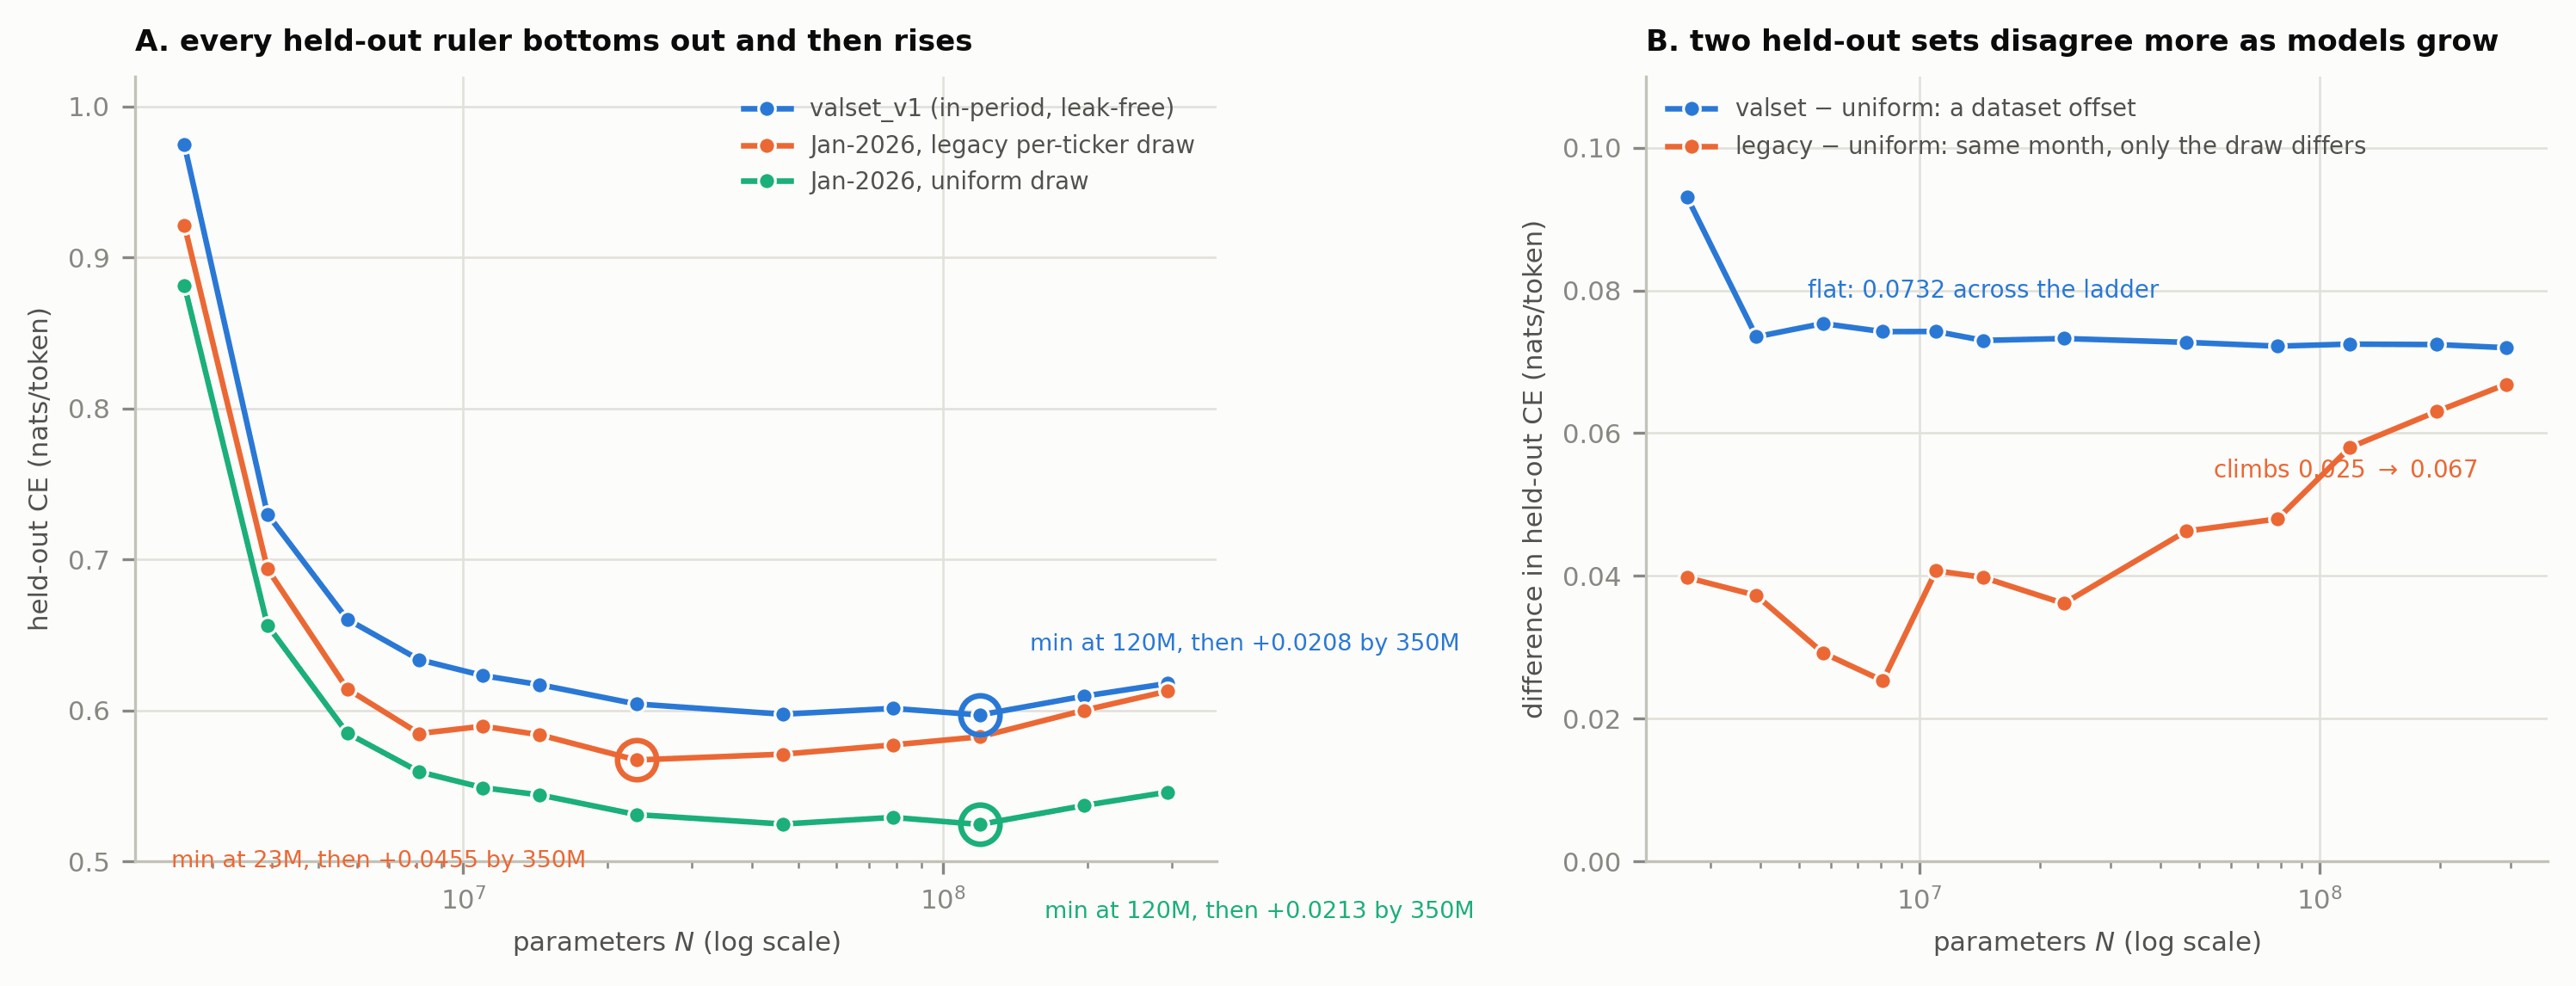

valset_v1 (in-period, leak-free)       min 0.5971 at  120M (119,279,919)  ->  350M 0.6179  rise +0.0208
Jan-2026, legacy per-ticker draw       min 0.5672 at   23M (22,949,247)  ->  350M 0.6128  rise +0.0455
Jan-2026, uniform draw                 min 0.5246 at  120M (119,279,919)  ->  350M 0.5459  rise +0.0213

             axis    alpha  alpha_at_search_bound        E best_size_on_this_ruler
    jan2026_macro 2.000000                   True 0.555200                     23M
     valset_macro 1.922188                  False 0.595692                    120M
jan_shuffle_macro 1.892724                  False 0.523363                    120M


In [9]:
RULERS = [("valset_macro", "valset_v1 (in-period, leak-free)", BLUE),
          ("jan2026_ticker_equal_macro", "Jan-2026, legacy per-ticker draw", ORANGE),
          ("jan2026_shuffle_macro", "Jan-2026, uniform draw", AQUA)]
r = ruler.sort_values("n_params").reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(9.98, 3.82), gridspec_kw={"width_ratios": [1.2, 1]})

ax = axes[0]
OFFSETS = [(14, 18), (-14, -30), (18, -26)]   # each callout gets its own corner
for (col, name, c), off in zip(RULERS, OFFSETS):
    ax.plot(r.n_params, r[col], "-o", color=c, ms=4.68, mec=SURFACE, mew=0.78, zorder=3, label=name)
    j = int(r[col].values.argmin())
    ax.plot(r.n_params[j], r[col][j], "o", ms=10.92, mfc="none", mec=c, mew=1.56, zorder=4)
    ax.annotate(f"min at {r['size'][j]}, then +{r[col].iloc[-1] - r[col][j]:.4f} by 350M",
                (r.n_params[j], r[col][j]), xytext=off, textcoords="offset points",
                fontsize=6.47, color=c, ha="left" if off[0] > 0 else "right")
ax.set_xscale("log"); ax.set_ylim(0.50, 1.02)
ax.legend(loc="upper right", fontsize=6.63, labelcolor=INK2)
tidy(ax, "parameters $N$ (log scale)", "held-out CE (nats/token)",
     "A. every held-out ruler bottoms out and then rises")

ax = axes[1]
d_val = r.valset_macro - r.jan2026_shuffle_macro
d_leg = r.jan2026_ticker_equal_macro - r.jan2026_shuffle_macro
ax.plot(r.n_params, d_val, "-o", color=BLUE, ms=4.68, mec=SURFACE, mew=0.78, zorder=3,
        label="valset $-$ uniform: a dataset offset")
ax.plot(r.n_params, d_leg, "-o", color=ORANGE, ms=4.68, mec=SURFACE, mew=0.78, zorder=3,
        label="legacy $-$ uniform: same month, only the draw differs")
ax.set_xscale("log"); ax.set_ylim(0, 0.11)
ax.annotate(f"flat: {d_val.iloc[1:].mean():.4f} across the ladder", (r.n_params.iloc[5], d_val.iloc[5]),
            xytext=(0, 12), textcoords="offset points", fontsize=6.63, color=BLUE, ha="center")
ax.annotate(f"climbs {d_leg.min():.3f} $\\rightarrow$ {d_leg.iloc[-1]:.3f}",
            (r.n_params.iloc[-1], d_leg.iloc[-1]), xytext=(-8, -26), textcoords="offset points",
            fontsize=6.63, color=ORANGE, ha="right")
ax.legend(loc="upper left", fontsize=6.63, labelcolor=INK2)
tidy(ax, "parameters $N$ (log scale)", "difference in held-out CE (nats/token)",
     "B. two held-out sets disagree more as models grow")
fig.tight_layout(); show(fig)

for col, name, _ in RULERS:
    j = int(r[col].values.argmin())
    print(f"{name:38s} min {r[col][j]:.4f} at {r['size'][j]:>5} "
          f"({int(r.n_params[j]):,})  ->  350M {r[col].iloc[-1]:.4f}  rise +{r[col].iloc[-1]-r[col][j]:.4f}")
print()
print(axis_fits[axis_fits.window == "last25"][
    ["axis", "alpha", "alpha_at_search_bound", "E", "best_size_on_this_ruler"]].to_string(index=False))

*A minimum in $N$ exists on all three held-out rulers and its location depends on which one you
use (23M against 120M), so "the bottom of the loss" is a quantity only validation data defines --
and defining it still requires naming the ruler.*

## Table 1 - the field decomposition, all three matched slices

In [10]:
T1 = fld_r[["field", "width", "train", "valset", "held", "memorisation", "tshift",
            "band", "mem_resolved", "mem_share", "unigram_nats", "recovered_pct"]].copy()
T1.columns = ["field", "w", "A train", "C leak-free", "B after window", "memorisation",
              "shift", "95% band", "mem resolved", "% of memorisation", "unigram", "% recovered"]
T1.sort_values("% of memorisation", ascending=False).round(4)

,field,w,A train,C leak-free,B after window,memorisation,shift,95% band,mem resolved,% of memorisation,unigram,% recovered
0,delta_t_ns,3,2.8447,3.0654,3.2461,0.2207,0.1807,0.0895,True,43.8765,3.2861,6.7173
1,time_ns_ref,3,1.4856,1.7013,1.7692,0.2157,0.0679,0.0895,True,42.8934,4.0934,58.4379
3,size,2,0.4210,0.4859,0.5135,0.0649,0.0276,0.1096,False,8.6019,1.0048,51.6455
4,event_type,1,0.5913,0.7197,0.7191,0.1283,-0.0006,0.1550,False,8.5060,0.7486,3.8633
5,time_ns,3,0.1213,0.1495,0.1558,0.0282,0.0063,0.0895,False,5.6093,6.8329,97.8117
8,direction,1,0.3241,0.3635,0.3830,0.0395,0.0194,0.1550,False,2.6152,0.6914,47.4179
7,time_s_ref,2,0.1672,0.1866,0.1996,0.0194,0.0130,0.1096,False,2.5748,2.8563,93.4663
10,size_ref,2,0.0140,0.0144,0.0106,0.0005,-0.0039,0.1096,False,0.0612,1.0187,98.5836
9,time_s,2,0.0163,0.0164,0.0147,0.0001,-0.0017,0.1096,False,0.0076,4.2049,99.6105
11,delta_t_s,1,0.0007,0.0001,0.0003,-0.0006,0.0002,0.1550,False,-0.0430,0.0007,NaN


## Table 2 - every claim in play, and the column it needs

In [11]:
p10r = 100 * (p10.unigram_nats - p10.valset) / p10.unigram_nats
p25r = 100 * (p25.unigram_nats - p25.valset) / p25.unigram_nats
rows = [
    ("the training loss has bottomed out near the conditional entropy",
     "leak-free CE", "invalid: no inequality relates train CE to H(p)", "Figure 1"),
    ("0.55-0.58 nats/token is the floor",
     "leak-free CE", f"train reads {BITS_TR:.2f} bits/msg; the in-window floor is "
                     f"{BITS_VA:.2f}", "Figure 1"),
    ("memorisation is not the main story at this depth",
     "all three", f"it is exactly half: {MEM:+.5f} against {SHIFT:+.5f}", "Figures 2, 6"),
    ("the gap is really distribution shift",
     "all three", "also half; neither reading was usable alone", "Figures 2, 6"),
    ("delta_t_ns is near-irreducible timing noise",
     "leak-free CE", f"recovers {fld[fld.field=='delta_t_ns'].recovered_pct.iloc[0]:.1f}% of "
                     f"unigram, yet memorisation alone is "
                     f"{fld[fld.field=='delta_t_ns'].memorisation.iloc[0]:+.4f}", "Figure 3"),
    ("positions 10 and 25 are a 7.57 bits/msg irreducible floor",
     "leak-free CE", f"pos 10 recovers {p10r:.0f}%, pos 25 recovers {p25r:.0f}%; 7.57 matches "
                     f"neither {p10.valset/LN2:.2f} (pos 10) nor "
                     f"{(p10.valset+p25.valset)/LN2:.2f} (both)", "Figure 4"),
    ("the +0.089 event_type gap is a finding",
     "all three", f"memorisation {fld[fld.field=='event_type'].memorisation.iloc[0]:+.4f} "
                  f"against a band of "
                  f"{fld_r[fld_r.field=='event_type'].band.iloc[0]:.4f}", "Figure 7"),
    ("CE inside the training window is stable enough to difference across",
     "leak-free CE", "no: it is the largest effect measured here", "Figure 5"),
    ("the floor is size-invariant across 25x in N",
     "leak-free CE", "untested here; on held-out rulers CE is not even monotone in N", "Figure 8"),
    ("more capacity is not justified by CE",
     "leak-free CE", "supported, and stronger than stated: CE rises after 23M-120M "
                     "on all three rulers", "Figure 8"),
]
T2 = pd.DataFrame(rows, columns=["claim", "needs", "what the committed data says", "where"])
pd.set_option("display.max_colwidth", 82)
T2

,claim,needs,what the committed data says,where
0,the training loss has bottomed out near the conditional entropy,leak-free CE,invalid: no inequality relates train CE to H(p),Figure 1
1,0.55-0.58 nats/token is the floor,leak-free CE,train reads 25.67 bits/msg; the in-window floor is 27.85,Figure 1
2,memorisation is not the main story at this depth,all three,it is exactly half: +0.05803 against +0.05827,"Figures 2, 6"
3,the gap is really distribution shift,all three,also half; neither reading was usable alone,"Figures 2, 6"
4,delta_t_ns is near-irreducible timing noise,leak-free CE,"recovers 6.7% of unigram, yet memorisation alone is +0.2207",Figure 3
5,positions 10 and 25 are a 7.57 bits/msg irreducible floor,leak-free CE,"pos 10 recovers 7%, pos 25 recovers 49%; 7.57 matches neither 7.20 (pos 10) no...",Figure 4
6,the +0.089 event_type gap is a finding,all three,memorisation +0.1283 against a band of 0.1550,Figure 7
7,CE inside the training window is stable enough to difference across,leak-free CE,no: it is the largest effect measured here,Figure 5
8,the floor is size-invariant across 25x in N,leak-free CE,untested here; on held-out rulers CE is not even monotone in N,Figure 8
9,more capacity is not justified by CE,leak-free CE,"supported, and stronger than stated: CE rises after 23M-120M on all three rulers",Figure 8


## Conclusions

1. **The floor is the leak-free, in-window number** (Figure 1). Train CE bounds nothing --
   $\mathbb{E}_p[-\log q] \ge H(p)$ holds only off the fitting sample -- and reads 2.18
   bits/msg below it. The after-the-window slice is a valid bound but on a different
   distribution, and reads 2.19 above. The two numbers the first pass had bracket the answer
   almost symmetrically, and neither is it.
2. **Most of the in-sample advantage is the calendar, not memory** (Figures 2, 3, 5). CE on
   never-trained data falls monotonically year over year -- 1.124, 1.088, 0.844, 0.742 --
   and keeps falling inside 2025, so December sits below the eleven-month mean it was
   differenced against on period alone. Correcting for the within-2025 slope takes the
   memorisation term from +0.058 to +0.024, which is 1.0 sigma. The extrapolation behind
   that number is weak on its own, but Figure 3 needs none of it: across the twelve fields
   the in-sample advantage tracks the period effect at $r = +0.74$ and $+0.77$.
3. **The residual sits on a reference field, not on the one the floor claim names**
   (Figure 3). `time_ns_ref` is 3.4x above what period predicts for it while `delta_t_ns` is
   at 0.43x -- less than period alone accounts for. A timestamp the model copies out of its
   own context is where memorised values would show up; the nanosecond inter-arrival digit
   is where they would not. So the earlier reading of `delta_t_ns` as recalled rather than
   predicted does not survive the period slices.
4. **The 7.57 bits/msg claim still merges two different positions** (Figure 4), and this is
   independent of everything above. Read on the leak-free slice, position 10 recovers 5% of
   its context-free entropy and position 25 recovers 47%: one is close to irreducible, the
   other is a reference the model has half solved, and the cited figure matches neither.
   Separately, at 128 sequences the eval budget is still sixty times under
   `test_ce_eval_spec.md` line 42, enough for the aggregate and the two nanosecond fields
   and not for the rest (Figure 7).